# 🍷 Classificando a qualidade de vinhos com Machine Learning
**Tech Challenge — Fase 2 | POSTECH Data Analytics (FIAP)**

**Integrantes:** Evanio Alves Carvalho · Michael Alves Pateis dos Santos · Guilherme Castilho Feitosa · Natália de Santana Cavalcanti

## 📋 Resumo executivo
**Pergunta de negócio:** as medidas de laboratório coletadas na produção conseguem antecipar quais vinhos os especialistas vão considerar de **alta qualidade** (nota ≥ 7)? E o que a produção pode fazer para ter mais deles?

**Resposta curta: sim.** Os principais resultados:

| # | Achado | Evidência |
|---|---|---|
| 1 | **Vinhos excelentes são raros**: 1 em cada 7 | 137 de 1.018 vinhos (13,5%) após remover 125 registros duplicados |
| 2 | **Três medidas explicam a diferença**: teor alcoólico (↑), acidez volátil (↓) e sulfatos (↑, até uma faixa ideal) | Têm os **maiores tamanhos de efeito** (0,50 a 0,65; as demais vão até 0,40), são significativas mesmo com correção de Bonferroni (p < 0,001) e são as mais importantes no modelo |
| 3 | **Os sinais se somam** | Com álcool ≥ 12% e acidez volátil < 0,4 g/L, 56% dos vinhos são excelentes; com álcool < 10% e acidez volátil ≥ 0,6 g/L, nenhum dos 185 é |
| 4 | **O modelo escolhido (Random Forest) encontra quase 4 em cada 5 vinhos excelentes** em vinhos nunca vistos | Recall de 78% (21 de 27; intervalo de 95%: 59% a 89%), F1 de 0,59 e ROC AUC de 0,92. Escolhido pela validação cruzada, entre 5 modelos |
| 5 | **Triagem: avaliar 30% dos lotes encontra 93% dos excelentes** | Curva de triagem na base de teste (25 de 27; intervalo de 95%: 77% a 98%). Sem o modelo, seriam ~30% |
| 6 | **As faixas de chance acompanham a realidade** | Lotes com chance ≥ 40%: 65% eram excelentes. Lotes com chance < 10% (70% dos lotes): apenas 1,4% eram |
| 7 | **O perfil completo multiplica a chance** | Simulador: um vinho típico tem ~2% de chance; as duas metas de processo (álcool e acidez volátil) juntas a triplicam (~6%); o perfil completo dos excelentes, com sulfatos na faixa de referência, chega a ~24% |
| 8 | **Impacto operacional** | A cada 1.000 lotes, ~700 de baixo potencial poderiam ir para uma avaliação simplificada: **~70% menos avaliações completas**, mantendo ~93% dos excelentes no fluxo prioritário |

**Recomendações:** (1) usar o modelo para **priorizar a avaliação sensorial** dos lotes; (2) estabelecer **metas de processo** para teor alcoólico e acidez volátil; (3) tratar os **sulfatos como marcador** associado à qualidade (investigar a origem, sem elevar o SO₂ total); (4) monitorar a **acidez volátil** como alerta precoce; (5) validar tudo em **lotes-piloto** antes de mudar o processo em escala.

### Índice

| Etapa | Pergunta respondida |
|---|---|
| [1. Compreensão do problema](#s1) | Qual decisão de negócio queremos apoiar, o que significa cada medida e por que "alta qualidade" é nota ≥ 7? |
| [2. Análise exploratória (EDA)](#s2) | O que diferencia os vinhos excelentes? Quais medidas importam e por quê? |
| [3. Pré-processamento](#s3) | Como preparar os dados de forma confiável e sem vazamento de informação? |
| [4. Desenvolvimento de modelos](#s4) | Quais algoritmos testamos, como os ajustamos e se o SMOTE ajudaria? |
| [5. Avaliação dos modelos](#s5) | Qual modelo é melhor, é confiável e não "decorou" os dados? |
| [6. Interpretação e previsões de negócio](#s6) | Quais medidas mais pesam, quanto a triagem economiza, quanto isso vale e o que acontece "e se" mudarmos o processo? |
| [7. Conclusão](#s7) | Qual a resposta à pergunta de negócio e o que recomendamos? |
| [8. Verificação de reprodutibilidade](#s8) | Os números citados no texto batem com o que o código calculou nesta execução? |

> 🧭 **Leitura rápida (≈ 5 minutos):** este resumo → [6.3 Triagem](#s63) → [6.5 Faixas de ação](#s65) → [6.7 Impacto na operação e em R$](#s67) → [7. Conclusão](#s7).

> **Como executar:** rode as células em ordem (localmente com Jupyter ou no Google Colab, a partir da pasta `notebooks/`). As funções auxiliares ficam em `src/` e todos os gráficos e tabelas são salvos em `results/`.

In [1]:
# Configuração do ambiente: permite importar a pasta src/ a partir de notebooks/
import sys
import warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.config import (FEATURES, FEATURE_LABELS, TARGET, QUALITY_THRESHOLD,
                        RANDOM_STATE, RESULTS_DIR, FIGURES_DIR, MODEL_COLORS)
from src import data_preprocessing as prep
from src import eda
from src import modeling
from src import evaluation
from src import simulation

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
eda.set_style()
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
pd.set_option("display.max_columns", 30)

---
<a id="s1"></a>

## 1. Compreensão do problema

**Contexto.** A qualidade de um vinho é tradicionalmente avaliada por especialistas, em análises sensoriais (aroma, sabor, acidez, equilíbrio). Esse processo é subjetivo, demorado e só acontece no fim da produção, quando já não é possível corrigir o lote. Por outro lado, durante a produção já são coletadas **medidas físico-químicas** (acidez, teor alcoólico, sulfatos etc.). Se essas medidas anteciparem a avaliação dos especialistas, o produtor ganha uma ferramenta objetiva para **ajustar o processo**, **priorizar lotes** e **padronizar a qualidade**.

**Pergunta de negócio:** *a partir das medidas de laboratório, conseguimos identificar quais vinhos serão avaliados como de alta qualidade, e o que fazer na produção para ter mais deles?*

**Decisões que o projeto pretende apoiar:**
1. **Triagem:** quais lotes enviar primeiro para a avaliação sensorial (economia de tempo dos especialistas).
2. **Controle de processo:** quais medidas acompanhar e em que faixas (correção ainda durante a produção).
3. **Posicionamento comercial:** identificar cedo os lotes com potencial premium.

**Variável alvo.** A coluna `quality` é uma nota de 0 a 10 dada por especialistas. Conforme o enunciado, ela é transformada em uma **classificação binária**:

- **Alta qualidade (1):** nota ≥ 7
- **Baixa/Média qualidade (0):** nota < 7

Trata-se de um problema de **aprendizado supervisionado de classificação binária**.

**Ressalvas sobre a base:** os dados são de vinhos tintos da variedade portuguesa "Vinho Verde" e as medidas foram feitas no **vinho pronto**. Em uma vinícola, várias dessas análises (como a acidez volátil) podem ser feitas em etapas intermediárias, o que permitiria agir antes do fim do processo. Neste projeto, cada amostra é tratada como um **lote** de produção, para traduzir os resultados em decisões de negócio.

In [2]:
df_raw = prep.load_data()
print(f"Dimensão da base: {df_raw.shape[0]} linhas x {df_raw.shape[1]} colunas")
df_raw.head()

Dimensão da base: 1143 linhas x 13 colunas


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,7.400,0.700,0.000,1.900,0.076,11.000,34.000,0.998,3.510,0.560,9.400,5,0
1,7.800,0.880,0.000,2.600,0.098,25.000,67.000,0.997,3.200,0.680,9.800,5,1
2,7.800,0.760,0.040,2.300,0.092,15.000,54.000,0.997,3.260,0.650,9.800,5,2
3,11.200,0.280,0.560,1.900,0.075,17.000,60.000,0.998,3.160,0.580,9.800,6,3
4,7.400,0.700,0.000,1.900,0.076,11.000,34.000,0.998,3.510,0.560,9.400,5,4


In [3]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 1143 entries, 0 to 1142
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1143 non-null   float64
 1   volatile acidity      1143 non-null   float64
 2   citric acid           1143 non-null   float64
 3   residual sugar        1143 non-null   float64
 4   chlorides             1143 non-null   float64
 5   free sulfur dioxide   1143 non-null   float64
 6   total sulfur dioxide  1143 non-null   float64
 7   density               1143 non-null   float64
 8   pH                    1143 non-null   float64
 9   sulphates             1143 non-null   float64
 10  alcohol               1143 non-null   float64
 11  quality               1143 non-null   int64  
 12  Id                    1143 non-null   int64  
dtypes: float64(11), int64(2)
memory usage: 116.2 KB


Todas as variáveis são numéricas. A coluna `Id` é apenas um identificador da linha e será descartada.

### Dicionário de variáveis

| Variável (coluna) | Nome em português | O que mede | Unidade | Papel no vinho |
|---|---|---|---|---|
| `fixed acidity` | Acidez fixa | Ácidos não voláteis (principalmente tartárico e málico) | g/L (ácido tartárico) | Estrutura, frescor e estabilidade |
| `volatile acidity` | Acidez volátil | Ácidos que evaporam, principalmente o ácido acético | g/L (ácido acético) | Em excesso, aroma de vinagre (defeito) |
| `citric acid` | Ácido cítrico | Ácido presente em pequena quantidade | g/L | Frescor e equilíbrio de sabor |
| `residual sugar` | Açúcar residual | Açúcar que sobra após a fermentação | g/L | Doçura (os tintos da base são secos) |
| `chlorides` | Cloretos | Teor de sal | g/L (cloreto de sódio) | Salinidade; em excesso, prejudica o sabor |
| `free sulfur dioxide` | SO₂ livre | Parte ativa do conservante dióxido de enxofre | mg/L | Protege contra oxidação e micro-organismos |
| `total sulfur dioxide` | SO₂ total | SO₂ livre + SO₂ combinado | mg/L | Em excesso, perceptível no aroma; tem limite legal |
| `density` | Densidade | Massa por volume do vinho | g/cm³ | Depende do teor de álcool e de açúcar |
| `pH` | pH | Grau de acidez (escala de 0 a 14) | adimensional | Quanto menor, mais ácido; afeta cor e estabilidade |
| `sulphates` | Sulfatos | Teor de sulfato de potássio | g/L | Associado ao manejo do SO₂ e à composição mineral |
| `alcohol` | Teor alcoólico | Percentual de álcool | % vol. | Corpo e intensidade; resulta da maturação da uva |
| `quality` | Qualidade | Nota sensorial dada por especialistas | 0 a 10 | **Variável alvo** (base para a classe binária) |
| `Id` | Identificador | Número da linha | — | Descartado (não é informação do vinho) |

*Fonte das descrições: documentação do Wine Quality Dataset (Cortez et al., 2009), disponibilizada no Kaggle. As unidades em g/L equivalem a g/dm³.*

### 1.1 Criação da variável alvo binária

In [4]:
df_target = prep.create_target(df_raw)
df_target[["quality", TARGET]].drop_duplicates().sort_values("quality").reset_index(drop=True)

,quality,alta_qualidade
0,3,0
1,4,0
2,5,0
3,6,0
4,7,1
5,8,1


### 1.2 Por que o corte em nota ≥ 7?
O enunciado sugere o corte em 7. Antes de adotá-lo, verificamos se ele faz sentido para o negócio, comparando os cortes possíveis (na base sem duplicados):

In [5]:
base_cortes = df_target.drop(columns="Id").drop_duplicates()
cortes = pd.DataFrame([
    {"Corte": f"nota ≥ {c}",
     "Vinhos na classe 'alta'": int((base_cortes["quality"] >= c).sum()),
     "% da base": (base_cortes["quality"] >= c).mean()}
    for c in (6, 7, 8)
]).set_index("Corte")
cortes.style.format({"% da base": "{:.1%}"})

,Vinhos na classe 'alta',% da base
Corte,,
nota ≥ 6,546,53.6%
nota ≥ 7,137,13.5%
nota ≥ 8,15,1.5%


**Justificativa da escolha:**
- **Nota ≥ 6** colocaria **mais da metade** dos vinhos (~54%) como "alta qualidade". A nota 6 é a mais comum depois da 5, ou seja, representa um vinho **mediano**. Esse corte não diferencia o vinho excepcional e não responde à pergunta de negócio (identificar os vinhos premium).
- **Nota ≥ 8** deixaria apenas **15 vinhos** (~1,5%) na classe positiva, poucos demais para treinar e avaliar um modelo com confiança.
- **Nota ≥ 7** separa os **~13,5% de vinhos realmente acima do padrão**: é raro o suficiente para representar **excelência** (e, portanto, valor comercial premium), mas ainda tem exemplos suficientes (137) para o modelo aprender.

Por isso adotamos **nota ≥ 7 = alta qualidade**, conforme o enunciado, agora com justificativa de negócio e de dados. A consequência, tratada na EDA, é uma **base desbalanceada**.

---
<a id="s2"></a>

## 2. Análise Exploratória de Dados (EDA)

### 2.1 Qualidade dos dados: faltantes e duplicados

In [6]:
faltantes = df_raw.isnull().sum()
print("Valores faltantes por coluna:")
print(faltantes.to_string())
print(f"\nTotal de valores faltantes: {faltantes.sum()}")

sem_id = df_raw.drop(columns="Id")
n_dup = sem_id.duplicated().sum()
print(f"\nLinhas duplicadas (mesmas medidas e mesma nota, ignorando o Id): {n_dup} "
      f"({n_dup / len(sem_id):.1%} da base)")

Valores faltantes por coluna:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
Id                      0

Total de valores faltantes: 0

Linhas duplicadas (mesmas medidas e mesma nota, ignorando o Id): 125 (10.9% da base)


- **Não há dados faltantes.**
- Há **amostras duplicadas**: linhas com exatamente as mesmas 11 medidas e a mesma nota, diferindo apenas no `Id`. São **inconsistências**: o mesmo vinho registrado mais de uma vez. Se mantidas, o mesmo vinho poderia cair ao mesmo tempo no treino e no teste, e o modelo seria avaliado em exemplos que já "decorou", inflando as métricas. Por isso, elas são removidas. A EDA a seguir já usa a base sem duplicados.

In [7]:
df = prep.clean_data(df_target)
print(f"Base após remover Id e duplicados: {df.shape[0]} vinhos")
df.describe().T

Base após remover Id e duplicados: 1018 vinhos


,count,mean,std,min,25%,50%,75%,max
fixed acidity,"1,018.000",8.289,1.741,4.600,7.100,7.900,9.100,15.900
volatile acidity,"1,018.000",0.534,0.183,0.120,0.390,0.520,0.645,1.580
citric acid,"1,018.000",0.269,0.196,0.000,0.090,0.250,0.420,1.000
residual sugar,"1,018.000",2.524,1.315,0.900,1.900,2.200,2.600,15.500
chlorides,"1,018.000",0.087,0.049,0.012,0.070,0.079,0.090,0.611
free sulfur dioxide,"1,018.000",15.649,10.177,1.000,7.000,13.000,21.000,68.000
total sulfur dioxide,"1,018.000",46.326,33.124,6.000,21.000,38.000,62.000,289.000
density,"1,018.000",0.997,0.002,0.990,0.996,0.997,0.998,1.004
pH,"1,018.000",3.312,0.158,2.740,3.210,3.310,3.400,4.010
sulphates,"1,018.000",0.657,0.168,0.330,0.550,0.620,0.720,2.000


**Leitura da estatística descritiva:**
- As variáveis estão em **escalas muito diferentes**: `density` varia em torno de 0,99, enquanto `total sulfur dioxide` chega a centenas. Isso sinaliza a necessidade de **padronização** para modelos baseados em distância (KNN, SVM) ou em coeficientes (Regressão Logística).
- Em várias colunas o **máximo fica muito acima do 3º quartil** (`residual sugar`, `chlorides`, `total sulfur dioxide`, `sulphates`), o que indica **assimetria à direita e presença de outliers**.
- Não há valores impossíveis: nenhum valor negativo, pH entre 2,74 e 4,01 e densidade entre 0,990 e 1,004 (próxima à da água), faixas típicas de vinhos tintos. Os dados são **fisicamente consistentes**.

### 2.2 Variável alvo e balanceamento das classes

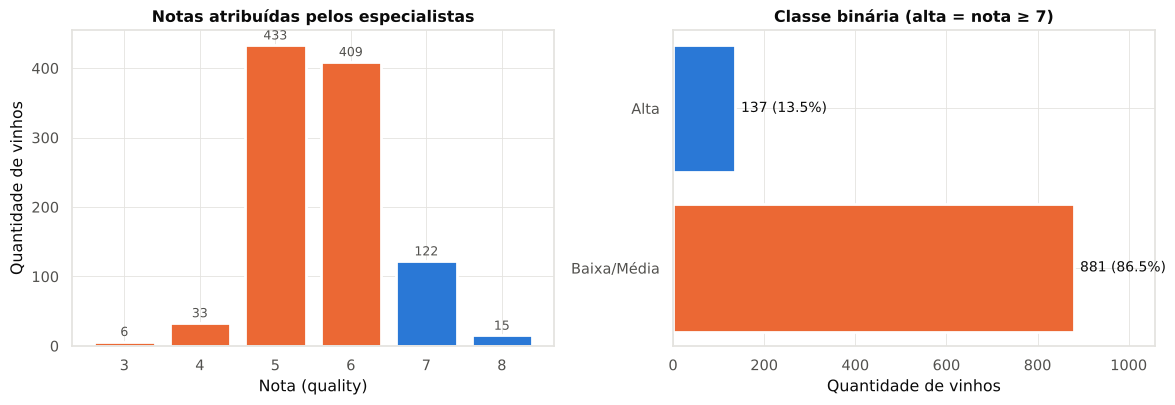

alta_qualidade
Baixa/Média   0.865
Alta          0.135
Name: proportion, dtype: float64


In [8]:
fig = eda.plot_quality_distribution(df, QUALITY_THRESHOLD,
                                    path=FIGURES_DIR / "01_distribuicao_qualidade.png")
plt.show()
print(df[TARGET].value_counts(normalize=True).rename({0: "Baixa/Média", 1: "Alta"}).round(3))

- As notas se concentram em **5 e 6**; notas extremas (3, 4 e 8) são raras.
- Após a binarização, apenas cerca de **1 em cada 7 vinhos é de alta qualidade**: as **classes são desbalanceadas**.

**Consequências para a modelagem:**
1. A **acurácia sozinha engana**: um modelo que dissesse "baixa/média" para todos os vinhos acertaria ~86%, sem identificar nenhum vinho bom.
2. A separação treino/teste e a validação cruzada são **estratificadas** (`stratify`), mantendo a proporção das classes.
3. Os modelos usam **`class_weight='balanced'`**, que dá mais peso aos vinhos de alta qualidade no treino.
4. As métricas principais são **F1-score, Recall, Precisão e ROC AUC** da classe de alta qualidade.

> 💼 **O que isso significa para o negócio:** vinhos excelentes são **raros e, por isso, valiosos**. Um sistema útil precisa **encontrá-los**, não apenas "acertar muito". Um sistema que nunca aponta um vinho premium teria 86% de acerto e valor zero para o negócio.

### 2.3 Distribuição das variáveis

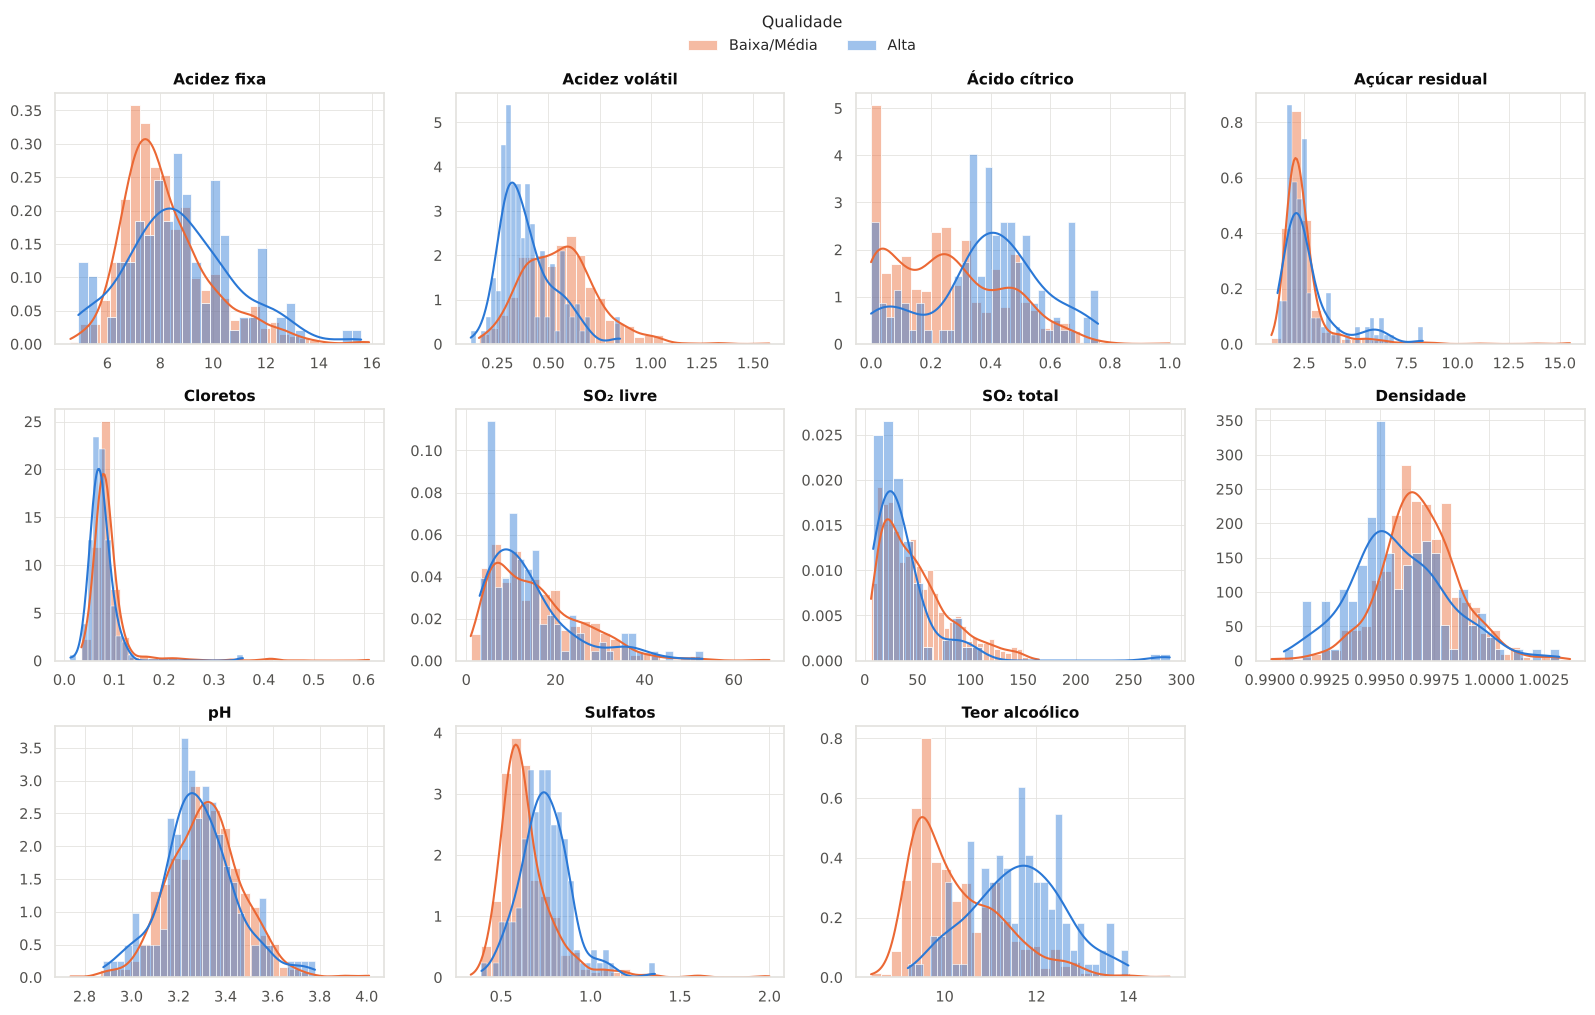

In [9]:
fig = eda.plot_histograms(df, path=FIGURES_DIR / "02_histogramas.png")
plt.show()

**Testes estatísticos.** Para complementar a análise visual:
- **Shapiro-Wilk** verifica se cada variável segue distribuição normal (H0: é normal).
- Como a normalidade é rejeitada, usamos o teste **não paramétrico de Mann-Whitney U** para verificar se a distribuição de cada variável difere entre vinhos de alta e de baixa/média qualidade (H0: as distribuições são iguais).
- Como fazemos 11 testes ao mesmo tempo, aplicamos a **correção de Bonferroni** (p × 11), que evita "descobertas" por acaso.
- Com mais de mil vinhos, até diferenças pequenas ficam estatisticamente significativas. Por isso medimos também o **tamanho do efeito** (correlação *rank-biserial*, de −1 a +1): abaixo de 0,3 é pequeno, de 0,3 a 0,5 é médio e acima de 0,5 é grande.

In [10]:
testes = eda.statistical_tests(df)
testes.to_csv(RESULTS_DIR / "testes_estatisticos.csv", index=False)
testes.style.format({
    "mediana_alta": "{:.3f}", "mediana_baixa_media": "{:.3f}", "shapiro_p": "{:.1e}",
    "mann_whitney_p": "{:.1e}", "p_bonferroni": "{:.1e}", "tamanho_efeito": "{:+.2f}",
})

,variavel,mediana_alta,mediana_baixa_media,normal? (Shapiro),shapiro_p,mann_whitney_p,p_bonferroni,significativa (Bonferroni)?,tamanho_efeito,efeito
0,Teor alcoólico,11.700,10.000,não,1.5e-21,6.9e-35,7.6e-34,sim,+0.65,grande
1,Acidez volátil,0.360,0.550,não,2.5e-13,2.0e-25,2.2e-24,sim,-0.55,grande
2,Sulfatos,0.740,0.600,não,1.2e-31,1.0e-20,1.1e-19,sim,+0.50,médio
3,Ácido cítrico,0.400,0.240,não,3.0e-17,8.8e-14,9.6e-13,sim,+0.40,médio
4,Cloretos,0.071,0.080,não,1.4e-47,6.8e-10,7.5e-09,sim,-0.33,médio
5,Densidade,0.995,0.997,não,8.8e-06,3.9e-08,4.3e-07,sim,-0.29,pequeno
6,SO₂ total,27.000,41.000,não,9.3e-29,7.9e-07,8.7e-06,sim,-0.26,pequeno
7,Acidez fixa,8.600,7.800,não,5.7e-20,3.5e-04,3.8e-03,sim,+0.19,pequeno
8,SO₂ livre,12.000,14.000,não,1.9e-24,1.6e-02,1.8e-01,não,-0.13,pequeno
9,pH,3.270,3.310,não,1.3e-05,2.2e-02,2.5e-01,não,-0.12,pequeno


**Interpretação das distribuições:**
- **Nenhuma variável segue distribuição normal** (Shapiro-Wilk com p < 0,05 em todas). Por isso, usamos testes não paramétricos e a correlação de **Spearman** além da de Pearson.
- `residual sugar`, `chlorides` e `sulphates` têm **forte assimetria à direita** (cauda longa de valores altos).
- Após a correção de Bonferroni, **8 das 11 variáveis diferem significativamente** entre as classes. **Açúcar residual, pH e SO₂ livre** não diferem.
- **O tamanho do efeito separa o que importa de verdade:** **teor alcoólico (+0,65) e acidez volátil (−0,55)** têm **efeito grande**, e os **sulfatos (+0,50)** ficam exatamente no limite entre médio e grande. Ácido cítrico (+0,40) e cloretos (−0,33) têm efeito médio, e as demais, efeito pequeno. As mesmas três medidas lideram a importância no modelo (seção 6.1).
- Os histogramas mostram **deslocamentos claros** em `alcohol` (vinhos bons são mais alcoólicos), `volatile acidity` (vinhos bons têm menos acidez volátil) e `sulphates` (vinhos bons têm mais sulfatos).

### 2.4 Outliers

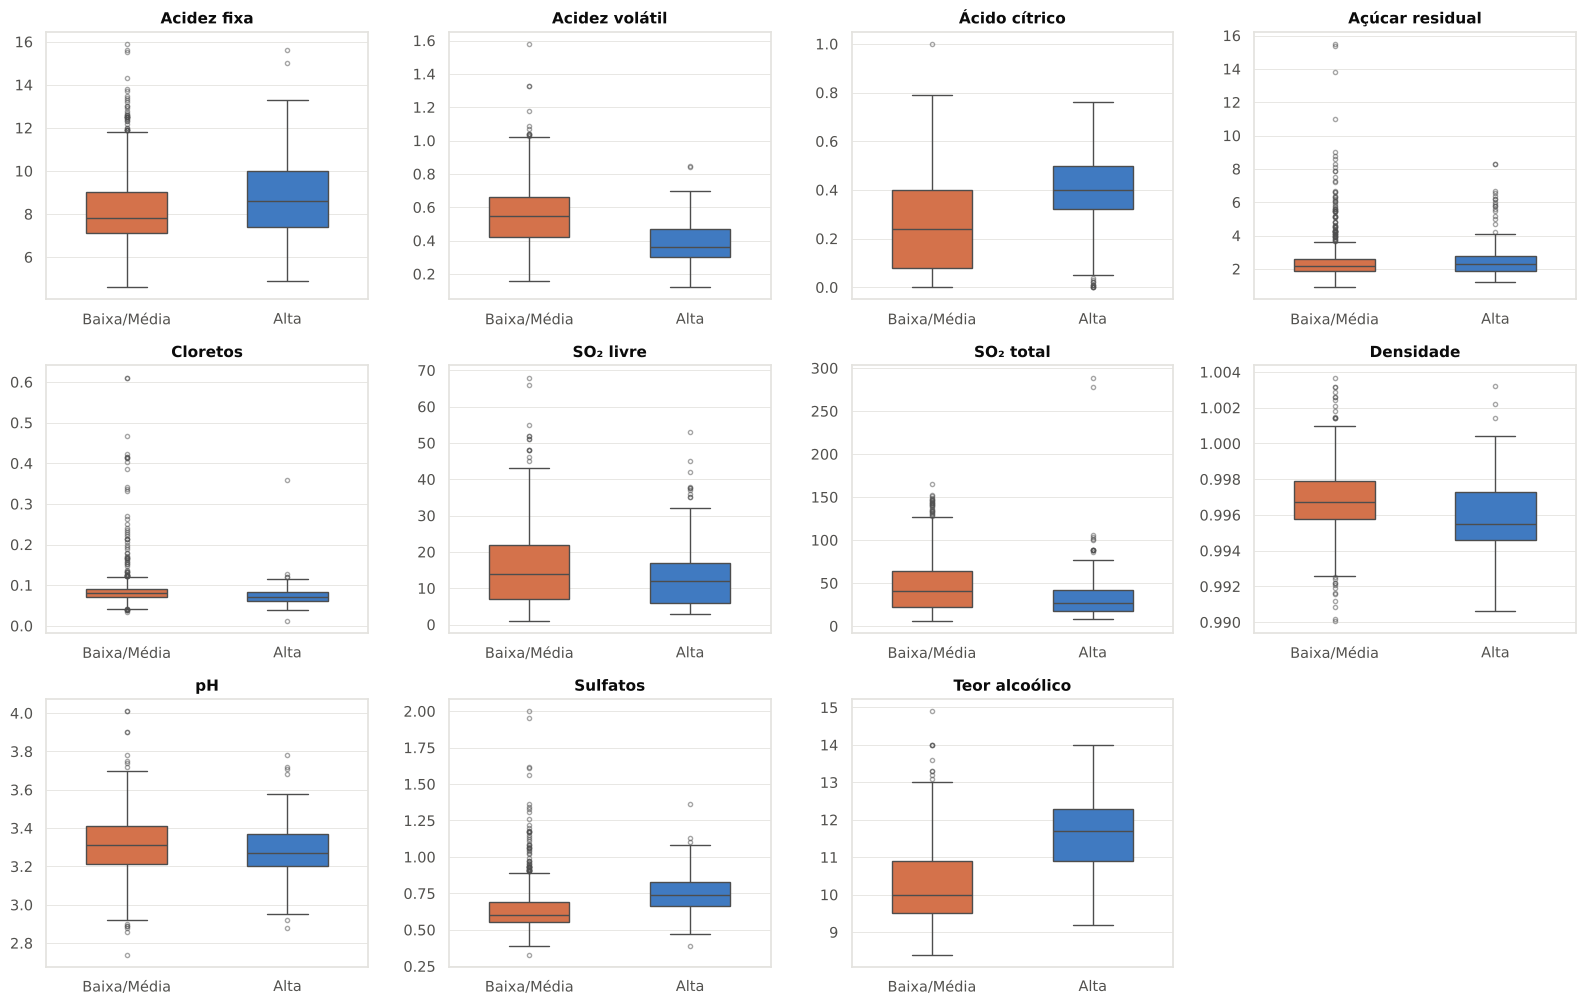

,outliers,percentual
residual sugar,95,9.300
chlorides,71,7.000
sulphates,41,4.000
fixed acidity,37,3.600
total sulfur dioxide,33,3.200
density,30,2.900
pH,24,2.400
free sulfur dioxide,16,1.600
volatile acidity,10,1.000
alcohol,6,0.600


In [11]:
fig = eda.plot_boxplots(df, path=FIGURES_DIR / "03_boxplots_por_classe.png")
plt.show()
outliers = prep.iqr_outlier_counts(df)
outliers.to_csv(RESULTS_DIR / "outliers_iqr.csv")
outliers

Pelo critério do IQR (valores além de 1,5 × IQR dos quartis), `residual sugar`, `chlorides`, `sulphates` e `fixed acidity` concentram mais outliers.

**Decisão: manter os outliers.** Outlier não é sinônimo de erro, e não se deve "sair deletando". Aqui os valores extremos são **quimicamente plausíveis**: vinhos com mais açúcar residual ou mais cloretos existem de fato. Nenhum valor é impossível, e remover as ~26% das linhas que têm ao menos um outlier eliminaria justamente vinhos diferentes do padrão, que o modelo precisa aprender a reconhecer. Para reduzir o efeito das escalas, usamos **padronização** nos modelos sensíveis a distância. Os modelos de **árvore** já são naturalmente robustos a outliers.

### 2.5 Correlações

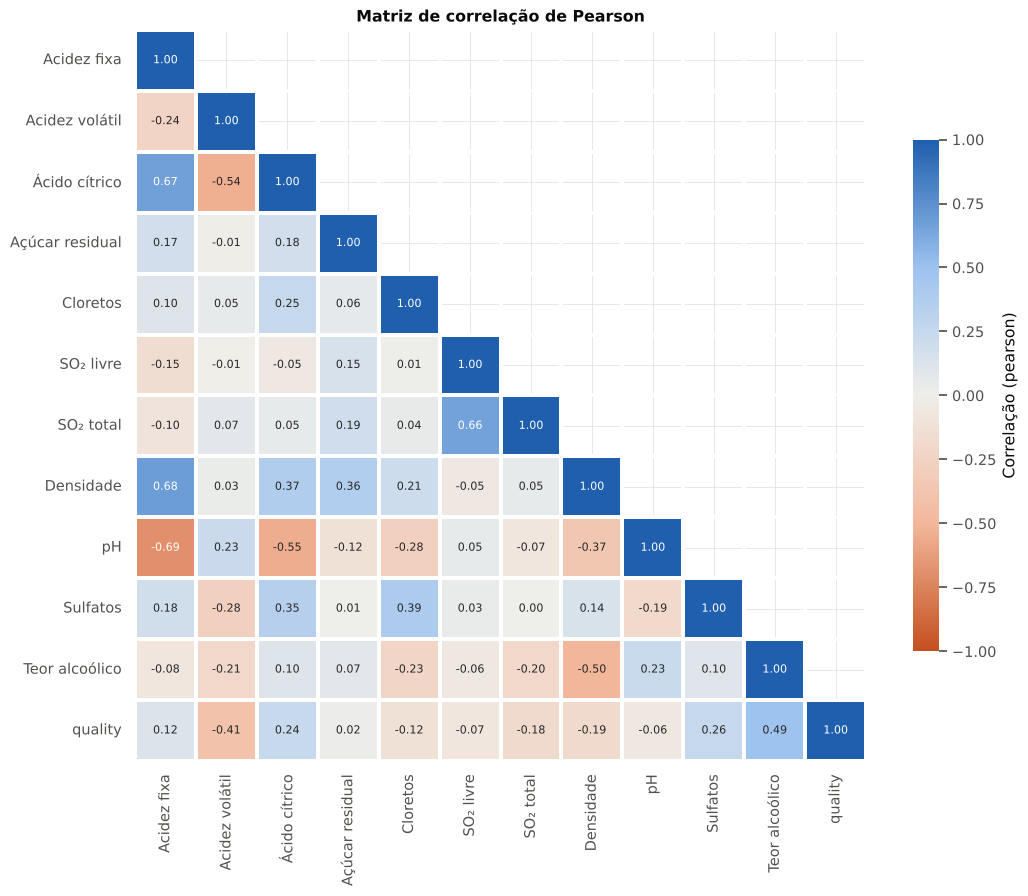

In [12]:
fig = eda.plot_correlation_heatmap(df, FEATURES + ["quality"], method="pearson",
                                   path=FIGURES_DIR / "04_correlacao_pearson.png")
plt.show()

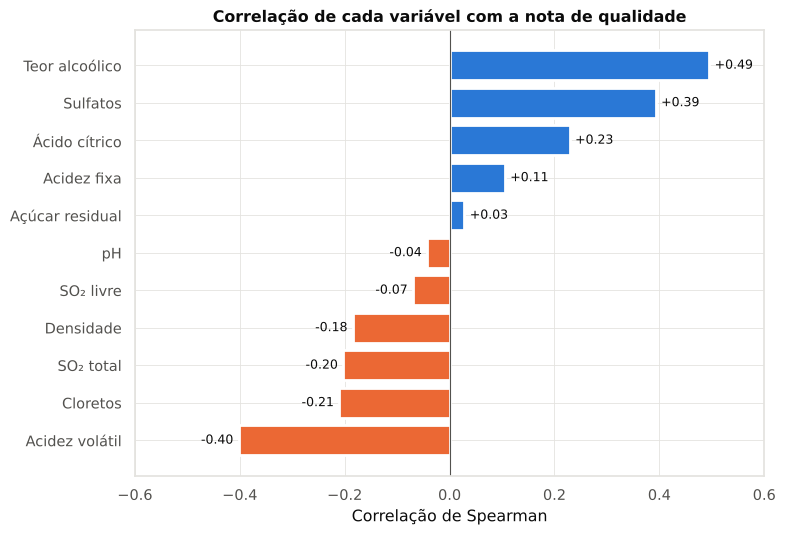

In [13]:
fig = eda.plot_target_correlation(df, path=FIGURES_DIR / "05_correlacao_com_qualidade.png")
plt.show()

In [14]:
corr_qual = pd.DataFrame({
    "Pearson": df[FEATURES].corrwith(df["quality"]),
    "Spearman": df[FEATURES].corrwith(df["quality"], method="spearman"),
}).sort_values("Spearman", ascending=False)
corr_qual.index = [FEATURE_LABELS[c] for c in corr_qual.index]
corr_qual.to_csv(RESULTS_DIR / "correlacao_com_qualidade.csv")
corr_qual

,Pearson,Spearman
Teor alcoólico,0.486,0.495
Sulfatos,0.258,0.393
Ácido cítrico,0.242,0.229
Acidez fixa,0.116,0.105
Açúcar residual,0.023,0.028
pH,-0.058,-0.042
SO₂ livre,-0.071,-0.069
Densidade,-0.185,-0.184
SO₂ total,-0.182,-0.202
Cloretos,-0.122,-0.210


**Correlação de cada variável com a qualidade e sua justificativa**

Usamos as duas medidas: **Pearson** (relação linear) e **Spearman** (relação monotônica, baseada em postos, mais adequada para variáveis não normais e com outliers). Quando as duas diferem, isso também é informação.

| Variável | Pearson | Spearman | Força / sentido | Justificativa |
|---|---|---|---|---|
| **Teor alcoólico** | +0,49 | +0,49 | Positiva, a **mais forte** | Uvas mais maduras têm mais açúcar, que a fermentação converte em álcool. O álcool dá corpo, sensação de calor e intensidade aromática, atributos valorizados pelos avaliadores. |
| **Sulfatos** | +0,26 | +0,39 | Positiva, moderada | A descrição da base associa os sulfatos ao manejo do SO₂, o conservante que protege o vinho contra oxidação e micro-organismos. O teor de sulfatos também reflete a nutrição mineral da uva (potássio). **Atenção:** o SO₂ total, em si, tem relação **negativa** com a nota, então os sulfatos devem ser lidos como um **marcador associado à qualidade**, e não como algo a "adicionar mais". O **Spearman bem maior que o Pearson** indica relação **não linear**: a associação cresce até ~0,85 g/L e depois para de crescer (ver seção 2.7). |
| **Ácido cítrico** | +0,24 | +0,23 | Positiva, fraca a moderada | Traz frescor e ajuda no equilíbrio do sabor. Também está associado a menor acidez volátil (r = −0,54), ou seja, a vinhos mais "limpos". |
| **Acidez fixa** | +0,12 | +0,11 | Positiva, **fraca** | Os ácidos tartárico e málico dão estrutura e frescor, e os vinhos bons são ligeiramente mais ácidos (mediana 8,6 contra 7,8 g/L). O efeito próprio é pequeno: parte dele vem do ácido cítrico e da densidade, com os quais a acidez fixa é fortemente correlacionada. |
| **Açúcar residual** | +0,02 | +0,03 | **Nula** | Quase todos os tintos da base são secos (mediana de 2,2 g/L), então a pequena variação de açúcar não muda a percepção de qualidade. Não há diferença significativa entre as classes no Mann-Whitney (o mesmo vale para pH e SO₂ livre após a correção de Bonferroni). |
| **pH** | −0,06 | −0,04 | **Nula** | O pH varia numa faixa estreita (quase todo entre 3,0 e 3,6). O que importa da acidez já está capturado pela acidez fixa (r = −0,69 com o pH). |
| **SO₂ livre** | −0,07 | −0,07 | **Nula** | É a fração ativa do conservante. Nos níveis presentes na base, ela protege o vinho, mas não diferencia os bons dos medianos. |
| **Densidade** | −0,19 | −0,18 | Negativa, fraca | Não é uma causa em si: reflete a composição do vinho. O álcool é menos denso que a água (r = −0,50 entre densidade e álcool), então vinhos mais alcoólicos, e portanto melhores, são menos densos. |
| **SO₂ total** | −0,18 | −0,20 | Negativa, fraca | Em excesso, o SO₂ pode ser perceptível no aroma (pungente). Doses altas também costumam indicar a necessidade de mais conservante, por exemplo em uvas menos sãs. |
| **Cloretos** | −0,12 | −0,21 | Negativa, fraca | Indicam salinidade, que prejudica o equilíbrio do sabor. O **Spearman maior que o Pearson** mostra que alguns valores extremos (outliers) "diluem" a correlação linear, mas a tendência monotônica existe. |
| **Acidez volátil** | −0,41 | −0,40 | Negativa, a **2ª mais forte** | É formada principalmente por ácido acético, produzido por bactérias quando há oxigênio ou falhas de fermentação. Em excesso, dá aroma de vinagre, um **defeito** clássico do vinho. |

**Correlações entre as variáveis explicativas (multicolinearidade) e sua justificativa:**

| Par de variáveis | r (Pearson) | Justificativa |
|---|---|---|
| Acidez fixa × pH | −0,69 | O pH é a medida da acidez: mais ácidos significa pH menor. |
| Acidez fixa × densidade | +0,68 | Os ácidos fazem parte do extrato dissolvido no vinho, que aumenta a densidade. |
| Acidez fixa × ácido cítrico | +0,67 | O ácido cítrico é um dos ácidos fixos: os dois sobem juntos. |
| SO₂ livre × SO₂ total | +0,66 | O SO₂ livre é uma parte do SO₂ total. |
| Ácido cítrico × pH | −0,55 | Mais ácido cítrico deixa o vinho mais ácido (pH menor). |
| Acidez volátil × ácido cítrico | −0,54 | Bactérias presentes no vinho podem consumir o ácido cítrico e produzir ácido acético, o principal componente da acidez volátil. Por isso, vinhos com mais ácido cítrico preservado tendem a ter menos acidez volátil. |
| Densidade × álcool | −0,50 | O álcool é menos denso que a água. |
| Cloretos × sulfatos | +0,39 | Correlação moderada, sem uma causa química direta. Uma explicação provável é que as duas medidas refletem o conteúdo de sais minerais do vinho, que varia com a uva, o solo e o processo. |

Nenhuma correlação entre variáveis explicativas é extrema (|r| > 0,9), então **todas as variáveis foram mantidas**. A Regressão Logística usa regularização (parâmetro `C`), o que ajuda a lidar com a colinearidade moderada. Ela é retomada na interpretação (seção 6.1).

### 2.6 Taxa de excelência por faixa: os dois sinais mais fortes
As correlações resumem a relação em um único número. Para um gestor, é mais concreto ver **quantos vinhos são excelentes em cada faixa** de teor alcoólico e de acidez volátil.

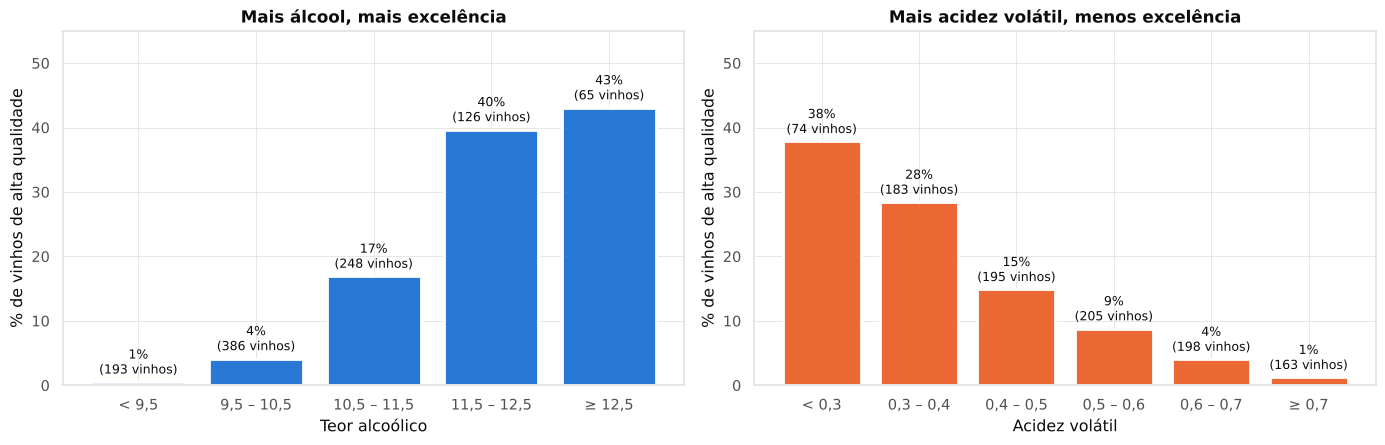

In [15]:
taxa_alcool = eda.quality_rate_by_bins(
    df, "alcohol", [0, 9.5, 10.5, 11.5, 12.5, 99],
    ["< 9,5", "9,5 – 10,5", "10,5 – 11,5", "11,5 – 12,5", "≥ 12,5"])
taxa_acidez = eda.quality_rate_by_bins(
    df, "volatile acidity", [0, 0.3, 0.4, 0.5, 0.6, 0.7, 9],
    ["< 0,3", "0,3 – 0,4", "0,4 – 0,5", "0,5 – 0,6", "0,6 – 0,7", "≥ 0,7"])
taxa_alcool.to_csv(RESULTS_DIR / "taxa_por_faixa_alcool.csv")
taxa_acidez.to_csv(RESULTS_DIR / "taxa_por_faixa_acidez_volatil.csv")

fig = eda.plot_quality_rate_by_bins(
    [("Mais álcool, mais excelência", taxa_alcool, "#2a78d6"),
     ("Mais acidez volátil, menos excelência", taxa_acidez, "#eb6834")],
    path=FIGURES_DIR / "14_taxa_por_faixa.png")
plt.show()

**Leitura:**
- **Teor alcoólico:** abaixo de 9,5%, praticamente nenhum vinho é excelente (1 em 193). Acima de 11,5%, cerca de **4 em cada 10** são (40% a 43%).
- **Acidez volátil:** com menos de 0,3 g/L, **38%** são excelentes; com 0,3 a 0,4 g/L, 28%. Acima de 0,7 g/L, só **1%** (2 em 163). A queda é contínua: cada degrau a mais de acidez volátil reduz a chance de excelência.

Esses são os números apresentados nos slides 5 e 6 da apresentação executiva.

### 2.7 Análise combinada: quando os sinais se somam
As análises anteriores olham uma variável de cada vez. Mas o especialista avalia o vinho **como um todo**. Cruzamos as duas medidas mais fortes, **teor alcoólico** e **acidez volátil**, para ver como elas atuam **juntas**.

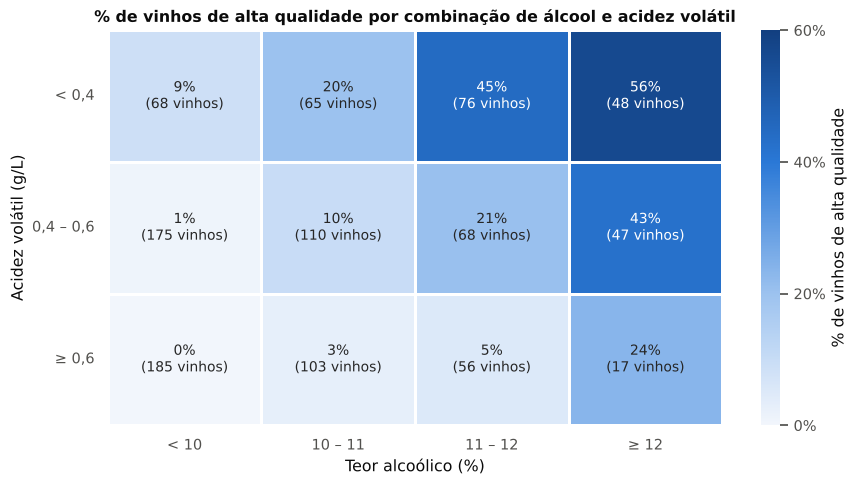

In [16]:
pct_comb, n_comb = eda.combined_quality_table(
    df,
    alcohol_bins=[0, 10, 11, 12, 99], alcohol_labels=["< 10", "10 – 11", "11 – 12", "≥ 12"],
    va_bins=[0, 0.4, 0.6, 9], va_labels=["< 0,4", "0,4 – 0,6", "≥ 0,6"],
)
pct_comb.to_csv(RESULTS_DIR / "combinacao_alcool_acidez.csv")
fig = eda.plot_combined_heatmap(pct_comb, n_comb, path=FIGURES_DIR / "06_mapa_alcool_acidez.png")
plt.show()

In [17]:
# Sulfatos: a relação é não linear (existe uma faixa "ideal")
faixas_sulf = pd.cut(df["sulphates"], [0, 0.55, 0.65, 0.75, 0.85, 9], right=False,
                     labels=["< 0,55", "0,55 – 0,65", "0,65 – 0,75", "0,75 – 0,85", "≥ 0,85"])
sulf = df.groupby(faixas_sulf, observed=False)[TARGET].agg(["mean", "size"])
sulf.columns = ["% alta qualidade", "vinhos"]
sulf

,% alta qualidade,vinhos
sulphates,,
"< 0,55",0.036,225
"0,55 – 0,65",0.056,376
"0,65 – 0,75",0.207,203
"0,75 – 0,85",0.339,112
"≥ 0,85",0.275,102


**O que a análise combinada revela:**
- Os efeitos **se somam**. Com **álcool ≥ 12% e acidez volátil < 0,4 g/L**, **56%** dos vinhos são de alta qualidade. Com **álcool < 10% e acidez volátil ≥ 0,6 g/L**, **nenhum** dos 185 vinhos é.
- **Álcool alto compensa só em parte a acidez volátil alta**: mesmo acima de 12% de álcool, a taxa cai de 56% para 24% quando a acidez volátil passa de 0,6 g/L.
- **Sulfatos têm uma faixa ideal**: a taxa de excelência sobe até 0,75 – 0,85 g/L (34%) e **não melhora** acima disso (28%; diferença dentro da variação esperada para ~100 vinhos por faixa). Mais não é sempre melhor, o que explica o Spearman maior que o Pearson.

### 2.8 Principais insights da EDA
1. **Álcool é o principal sinal de qualidade**: a mediana dos vinhos bons é ~1,7 ponto percentual maior (11,7% contra 10,0%).
2. **Acidez volátil é o principal sinal negativo**: os vinhos bons têm cerca de 35% menos (0,36 contra 0,55 g/L).
3. **Sulfatos e ácido cítrico** completam o perfil, com os sulfatos em uma **faixa ideal**, não "quanto mais, melhor".
4. **Os sinais se combinam**: o perfil "álcool alto + acidez volátil baixa" concentra os vinhos excelentes.
5. A base é **desbalanceada** (~13,5% de vinhos bons), o que exige métricas além da acurácia.
6. As variáveis **não são normais**, têm **escalas diferentes** e **outliers plausíveis**, o que exige padronização para KNN, SVM e Regressão Logística.

> 💼 **O que isso significa para o negócio:** já existe um **"perfil do vinho excelente"** mensurável em laboratório: **álcool acima de ~11,5%, acidez volátil abaixo de ~0,4 g/L e sulfatos entre ~0,65 e 0,85 g/L**. As duas primeiras podem virar **metas de controle de processo**. Os sulfatos funcionam como **marcador** de qualidade, cuja origem deve ser investigada. A acidez volátil, em especial, funciona como **sinal de alerta** que pode ser medido durante a produção, quando ainda dá para agir.

---
<a id="s3"></a>

## 3. Pré-processamento de dados

| Etapa | Decisão |
|---|---|
| Dados faltantes | Não há valores faltantes, então nenhuma imputação é necessária. |
| Duplicados | Removidos (passo já aplicado com `prep.clean_data`). |
| Outliers | Mantidos (valores plausíveis; ver seção 2.4). |
| Separação treino/teste | 80% / 20%, **estratificada** pela classe, `random_state=42`. |
| Escalonamento | **Padronização (`StandardScaler`, Z-score)** dentro de um `Pipeline` para KNN, SVM e Regressão Logística. Árvores não precisam. |
| Desbalanceamento | `class_weight='balanced'` e métricas focadas na classe minoritária. |
| Feature engineering | Três novas variáveis testadas (ver 3.2). |

**Por que padronização e não normalização (MinMax)?** A normalização usa o mínimo e o máximo de cada variável, então um único outlier "esmaga" todos os demais valores em uma faixa estreita. A padronização usa média e desvio padrão e é menos afetada pelos outliers que decidimos manter.

**Por que o escalonamento fica dentro do `Pipeline`?** Assim, a média e o desvio são calculados **apenas com os dados de treino** de cada fold da validação cruzada, evitando *vazamento de dados* (data leakage) do teste para o treino.

### 3.1 Separação treino/teste estratificada

In [18]:
X_train, X_test, y_train, y_test = prep.split_data(df, FEATURES)

resumo_split = pd.DataFrame({
    "Linhas": [len(y_train), len(y_test)],
    "Vinhos de alta qualidade": [y_train.sum(), y_test.sum()],
    "% alta qualidade": [y_train.mean() * 100, y_test.mean() * 100],
}, index=["Treino", "Teste"])
resumo_split

,Linhas,Vinhos de alta qualidade,% alta qualidade
Treino,814,110,13.514
Teste,204,27,13.235


A proporção de vinhos de alta qualidade é a mesma no treino e no teste, graças ao `stratify`. A base de teste fica **guardada** e só é usada no fim, como simulação de "vinhos novos".

### 3.2 Feature engineering
Criamos três variáveis com sentido enológico:
- **`free_so2_ratio`**: fração do SO₂ que está livre, ou seja, a parte que efetivamente protege o vinho.
- **`total_acidity`**: acidez total (fixa + volátil + cítrica).
- **`alcohol_x_sulphates`**: interação entre as duas variáveis mais associadas à alta qualidade, inspirada na análise combinada da seção 2.7.

Para decidir se vale a pena usá-las, comparamos o desempenho em **validação cruzada (apenas no treino)**, com e sem as novas variáveis.

In [19]:
df_fe = prep.add_features(df)
features_fe = FEATURES + prep.ENGINEERED_FEATURES
Xtr_fe, Xte_fe, ytr_fe, yte_fe = prep.split_data(df_fe, features_fe)

cv = modeling.get_cv()
comparacao_fe = {}
for nome_conjunto, (Xtr, ytr) in {
    "Originais (11)": (X_train, y_train),
    "Originais + novas (14)": (Xtr_fe, ytr_fe),
}.items():
    buscas_fe = modeling.tune_models(modeling.build_models(), Xtr, ytr, cv=cv)
    comparacao_fe[nome_conjunto] = {nome: b.best_score_ for nome, b in buscas_fe.items()}

comparacao_fe = pd.DataFrame(comparacao_fe)
comparacao_fe["Diferença"] = comparacao_fe.iloc[:, 1] - comparacao_fe.iloc[:, 0]
comparacao_fe.to_csv(RESULTS_DIR / "feature_engineering_f1_cv.csv")
print("F1 médio na validação cruzada (5 folds) — melhor configuração de cada modelo")
comparacao_fe

F1 médio na validação cruzada (5 folds) — melhor configuração de cada modelo


,Originais (11),Originais + novas (14),Diferença
Regressão Logística,0.525,0.525,-0.000
KNN,0.467,0.509,0.042
SVM,0.510,0.515,0.005
Árvore de Decisão,0.481,0.484,0.004
Random Forest,0.538,0.558,0.020


**Decisão:** o ganho das novas variáveis é **pequeno e inconsistente** entre os modelos (de −0,000 a +0,042 no F1), da mesma ordem da variação natural entre os folds da validação cruzada (desvios de 0,03 a 0,12, ver seção 5.1). Na Regressão Logística, o ganho é nulo. Seguindo o princípio de parcimônia, mantemos as **11 variáveis originais**: o modelo fica mais simples e mais fácil de explicar ao enólogo, sem perda relevante de desempenho. Isso também é um achado: **a informação relevante já está nas medidas originais**, e a interação entre elas é capturada naturalmente pelos modelos de árvore.

---
<a id="s4"></a>

## 4. Desenvolvimento dos modelos

Treinamos **cinco modelos de classificação** vistos nas disciplinas:

| Modelo | Como funciona (em uma frase) | Pré-processamento |
|---|---|---|
| **Regressão Logística** | Combina as variáveis em uma fórmula linear e converte o resultado em probabilidade. É simples e interpretável (baseline) | Padronização |
| **KNN** | Classifica o vinho pela maioria dos vinhos mais parecidos com ele (vizinhos mais próximos) | Padronização (usa distâncias) |
| **SVM** | Encontra a fronteira que melhor separa as duas classes, inclusive fronteiras curvas (kernel RBF) | Padronização (usa distâncias) |
| **Árvore de Decisão** | Cria regras do tipo "se álcool > X e acidez < Y, então...", fáceis de visualizar | Nenhum |
| **Random Forest** | Combina centenas de árvores treinadas em amostras diferentes. É mais robusto e menos sujeito a overfitting que uma árvore única | Nenhum |

**Ajuste de hiperparâmetros:** `GridSearchCV` com **validação cruzada estratificada de 5 folds** (`StratifiedKFold` com `shuffle=True`), otimizando o **F1-score** da classe de alta qualidade.

In [20]:
modelos = modeling.build_models()
buscas = modeling.tune_models(modelos, X_train, y_train, scoring="f1", cv=cv)

melhores = pd.DataFrame({
    nome: {"F1 médio (CV)": b.best_score_,
           "Melhores hiperparâmetros": {k.replace("model__", ""): v
                                        for k, v in b.best_params_.items()}}
    for nome, b in buscas.items()
}).T
melhores

,F1 médio (CV),Melhores hiperparâmetros
Regressão Logística,0.525,{'C': 100}
KNN,0.467,"{'metric': 'euclidean', 'n_neighbors': 7, 'wei..."
SVM,0.510,"{'C': 100, 'gamma': 0.01}"
Árvore de Decisão,0.481,"{'criterion': 'entropy', 'max_depth': 5, 'min_..."
Random Forest,0.538,"{'max_depth': None, 'min_samples_leaf': 5, 'n_..."


### 4.1 Alternativa para o desbalanceamento: oversampling com SMOTE
Nas aulas, vimos duas formas de lidar com classes desbalanceadas: **dar mais peso** à classe rara (`class_weight`, usado acima) ou **criar exemplos sintéticos** dela (*oversampling*). Testamos o **SMOTE**, que cria vinhos de alta qualidade "artificiais" interpolando vinhos reais parecidos. O SMOTE fica **dentro do Pipeline**, então só é aplicado ao treino de cada fold, e a avaliação continua sendo feita só com vinhos reais.

Comparamos as duas abordagens na **validação cruzada** (apenas treino) para os dois melhores modelos.

In [21]:
from sklearn.model_selection import cross_validate

buscas_smote = modeling.tune_models(modeling.build_smote_models(), X_train, y_train, cv=cv)
metricas_cv = {"F1": "f1", "ROC AUC": "roc_auc", "Recall": "recall", "Precisão": "precision"}

linhas = []
for nome, busca in [("Regressão Logística (class_weight)", buscas["Regressão Logística"]),
                    ("Regressão Logística + SMOTE", buscas_smote["Regressão Logística + SMOTE"]),
                    ("Random Forest (class_weight)", buscas["Random Forest"]),
                    ("Random Forest + SMOTE", buscas_smote["Random Forest + SMOTE"])]:
    r = cross_validate(busca.best_estimator_, X_train, y_train, cv=cv, scoring=metricas_cv)
    linhas.append({"Abordagem": nome, **{m: r["test_" + m].mean() for m in metricas_cv}})

comparacao_smote = pd.DataFrame(linhas).set_index("Abordagem")
comparacao_smote.to_csv(RESULTS_DIR / "comparacao_smote.csv")
comparacao_smote.style.format("{:.3f}").highlight_max(axis=0, color="#cfe0f5")

,F1,ROC AUC,Recall,Precisão
Abordagem,,,,
Regressão Logística (class_weight),0.525,0.871,0.827,0.386
Regressão Logística + SMOTE,0.521,0.870,0.800,0.388
Random Forest (class_weight),0.538,0.875,0.700,0.440
Random Forest + SMOTE,0.508,0.866,0.718,0.395


**Decisão:** o SMOTE **não melhora** o desempenho. No Random Forest, o F1 médio cai de 0,538 para 0,508 e o AUC também recua. Na Regressão Logística, os resultados são praticamente iguais. Uma explicação provável: com poucos vinhos excelentes e medidas que se sobrepõem bastante entre as classes, os exemplos sintéticos acrescentam "ruído" na fronteira entre as classes, em vez de informação nova. Mantemos, portanto, o **`class_weight='balanced'`**, que é mais simples e não cria dados artificiais.

---
<a id="s5"></a>

## 5. Avaliação dos modelos

### 5.1 Validação cruzada (base de treino)
A validação cruzada mostra a **estabilidade** de cada modelo: média ± desvio padrão do desempenho em 5 recortes diferentes da base de treino.

In [22]:
cv_resumo = evaluation.cross_validation_summary(buscas, X_train, y_train, cv)
cv_resumo.to_csv(RESULTS_DIR / "validacao_cruzada.csv")
cv_resumo

,F1 (CV),ROC AUC (CV),Recall (CV),Precisão (CV)
Regressão Logística,0.525 ± 0.033,0.871 ± 0.032,0.827 ± 0.067,0.386 ± 0.029
KNN,0.467 ± 0.123,0.795 ± 0.061,0.400 ± 0.101,0.561 ± 0.158
SVM,0.510 ± 0.079,0.838 ± 0.061,0.709 ± 0.137,0.401 ± 0.061
Árvore de Decisão,0.481 ± 0.058,0.798 ± 0.073,0.736 ± 0.194,0.365 ± 0.016
Random Forest,0.538 ± 0.077,0.875 ± 0.037,0.700 ± 0.134,0.440 ± 0.054


### 5.2 Desempenho na base de teste (dados nunca vistos)

In [23]:
metricas = evaluation.compare_models(buscas, X_test, y_test)
metricas.to_csv(RESULTS_DIR / "metricas_teste.csv")
metricas.style.highlight_max(axis=0, color="#cfe0f5").format("{:.3f}")

,Acurácia,Precisão,Recall,F1,ROC AUC
Regressão Logística,0.789,0.362,0.778,0.494,0.881
KNN,0.897,0.650,0.481,0.553,0.874
SVM,0.814,0.388,0.704,0.500,0.889
Árvore de Decisão,0.828,0.420,0.778,0.545,0.832
Random Forest,0.858,0.477,0.778,0.592,0.921


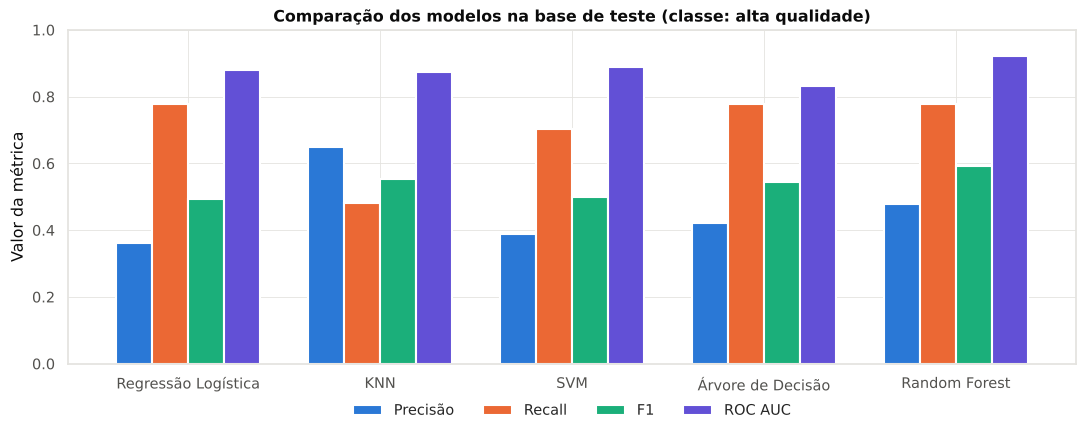

In [24]:
fig, ax = plt.subplots(figsize=(11, 4.5))
metricas[["Precisão", "Recall", "F1", "ROC AUC"]].plot.bar(
    ax=ax, color=["#2a78d6", "#eb6834", "#1baf7a", "#6250d6"],
    width=0.75, edgecolor="white", linewidth=1.5)
ax.set_ylim(0, 1)
ax.set_ylabel("Valor da métrica")
ax.set_title("Comparação dos modelos na base de teste (classe: alta qualidade)")
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
ax.legend(ncol=4, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.08))
fig.tight_layout()
fig.savefig(FIGURES_DIR / "07_comparacao_modelos.png", dpi=150, bbox_inches="tight")
plt.show()

### 5.3 Matrizes de confusão

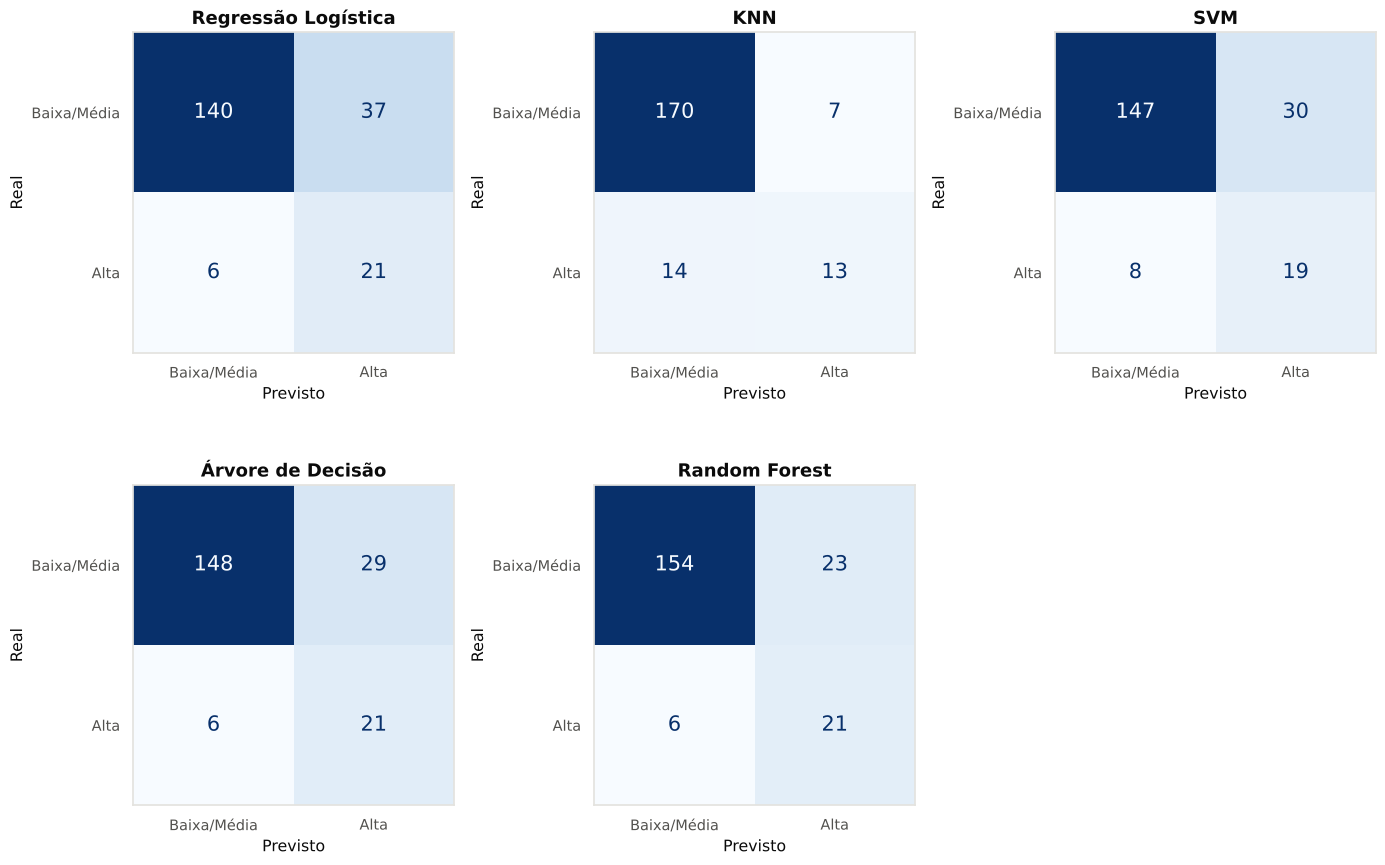

In [25]:
fig = evaluation.plot_confusion_matrices(buscas, X_test, y_test,
                                         path=FIGURES_DIR / "08_matrizes_confusao.png")
plt.show()

### 5.4 Curva ROC e AUC

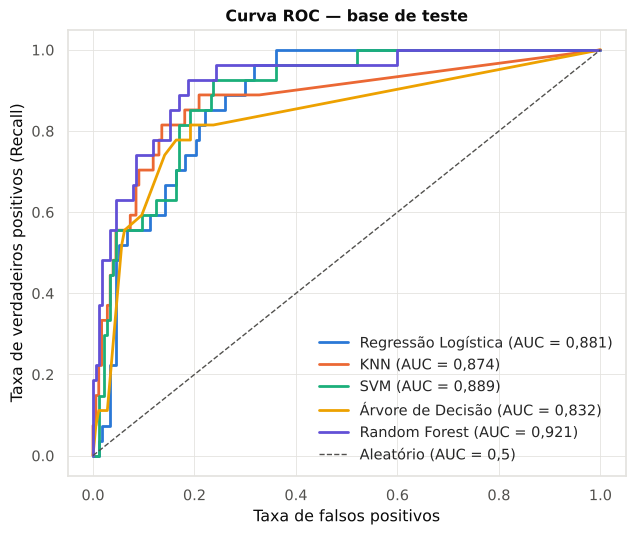

In [26]:
fig = evaluation.plot_roc_curves(buscas, X_test, y_test,
                                 path=FIGURES_DIR / "09_curva_roc.png")
plt.show()

### 5.5 Checagem de overfitting
Um modelo pode "decorar" a base de treino e falhar com vinhos novos. Comparamos o F1 no **treino**, na **validação cruzada** e no **teste**: quanto maior a distância entre o treino e os demais, maior o sobreajuste.

In [27]:
overfit = evaluation.overfitting_table(buscas, X_train, y_train, X_test, y_test)
overfit.to_csv(RESULTS_DIR / "checagem_overfitting.csv")
overfit

,F1 treino,F1 validação cruzada,F1 teste,Diferença treino − validação
Regressão Logística,0.533,0.525,0.494,0.008
KNN,1.000,0.467,0.553,0.533
SVM,0.632,0.510,0.500,0.122
Árvore de Decisão,0.631,0.481,0.545,0.151
Random Forest,0.743,0.538,0.592,0.206


**Leitura da checagem:**
- **Regressão Logística:** praticamente sem sobreajuste (diferença de 0,01). É o modelo mais **estável**, mas também o de menor capacidade de capturar relações não lineares.
- **KNN: F1 = 1,00 no treino.** Não é aprendizado real: com `weights='distance'`, cada vinho do treino é o seu próprio "vizinho" a distância zero, então o modelo sempre "acerta" o que já viu. A medida honesta é a validação cruzada (0,47), que também é a **mais instável** (± 0,12). Esse é o exemplo clássico de **modelo que decora os dados**.
- **Random Forest:** diferença moderada (0,74 no treino contra 0,54 na validação), esperada em florestas. Ela é controlada pelo hiperparâmetro `min_samples_leaf = 5`, escolhido pelo GridSearch, que impede folhas com poucos vinhos. O mais importante: **o desempenho no teste (0,59) não cai** em relação à validação, ou seja, o modelo **generaliza** para vinhos novos.
- **SVM e Árvore de Decisão:** sobreajuste moderado (0,12 e 0,15), com desempenho de teste inferior ao do Random Forest.

**Conclusão:** nenhum modelo "desaba" no teste. O Random Forest mantém o melhor desempenho em dados nunca vistos, e o KNN mostra por que a validação cruzada, e não o treino, deve guiar a escolha.

### 5.6 Classification report do melhor modelo

In [28]:
from sklearn.metrics import classification_report

# A escolha do modelo usa a VALIDAÇÃO CRUZADA (apenas treino).
# A base de teste serve só para confirmar o desempenho em dados nunca vistos.
melhor_nome = max(buscas, key=lambda nome: buscas[nome].best_score_)
melhor_modelo = buscas[melhor_nome].best_estimator_
print(f"Modelo escolhido (maior F1 na validação cruzada): {melhor_nome}")
print(f"Também é o maior F1 no teste? {metricas['F1'].idxmax() == melhor_nome}\n")
print(classification_report(y_test, melhor_modelo.predict(X_test),
                            target_names=["Baixa/Média", "Alta"], digits=3))

Modelo escolhido (maior F1 na validação cruzada): Random Forest
Também é o maior F1 no teste? True

              precision    recall  f1-score   support

 Baixa/Média      0.963     0.870     0.914       177
        Alta      0.477     0.778     0.592        27

    accuracy                          0.858       204
   macro avg      0.720     0.824     0.753       204
weighted avg      0.898     0.858     0.871       204



### 5.7 Ajuste do limiar de decisão: qual erro custa mais?
Por padrão, o modelo classifica como "alta qualidade" quando a pontuação prevista é ≥ 0,5. Mudar esse limiar troca **precisão** por **recall**:
- **Limiar mais baixo**: encontra mais vinhos bons (↑ recall), mas gera mais alarmes falsos (↓ precisão).
- **Limiar mais alto**: quando aponta um vinho como bom, acerta mais (↑ precisão), mas deixa passar vinhos bons (↓ recall).

A escolha depende do negócio. Se o objetivo é **separar lotes para uma linha premium**, um falso positivo (vender um vinho mediano como premium) prejudica a marca, então vale priorizar precisão. Se o objetivo é **triagem para avaliação dos especialistas**, deixar escapar um vinho bom é o pior erro, então vale priorizar recall.

> A tabela abaixo é **ilustrativa** do trade-off. Em produção, o limiar deveria ser escolhido em uma base de validação separada, e não no teste.

In [29]:
from sklearn.metrics import precision_score, recall_score, f1_score

prob = melhor_modelo.predict_proba(X_test)[:, 1]
limiares = pd.DataFrame([
    {"Limiar": t,
     "Vinhos apontados como alta": int((prob >= t).sum()),
     "Precisão": precision_score(y_test, prob >= t, zero_division=0),
     "Recall": recall_score(y_test, prob >= t),
     "F1": f1_score(y_test, prob >= t)}
    for t in [0.3, 0.4, 0.5, 0.6, 0.7]
]).set_index("Limiar")
limiares.to_csv(RESULTS_DIR / "trade_off_limiar.csv")
limiares

,Vinhos apontados como alta,Precisão,Recall,F1
Limiar,,,,
0.300,67,0.373,0.926,0.532
0.400,54,0.444,0.889,0.593
0.500,44,0.477,0.778,0.592
0.600,33,0.545,0.667,0.600
0.700,20,0.700,0.519,0.596


### 5.8 Comparação e escolha do modelo
| Modelo | Destaque | Ponto fraco |
|---|---|---|
| **Random Forest** | Melhor F1 (0,59) e melhor ROC AUC (0,92) no teste; também o melhor F1 e AUC na validação cruzada | Menos interpretável que uma árvore única; sobreajuste moderado (controlado) |
| **Regressão Logística** | Desempenho próximo do Random Forest na validação cruzada (AUC 0,871 vs 0,875), maior recall e **o modelo mais estável** | Muitos falsos positivos (precisão de ~0,36) |
| **SVM** | Bom AUC no teste (0,89) e recall de 70% | F1 menor (0,50) e mais alarmes falsos (30) que o Random Forest |
| **KNN** | Maior **acurácia** (0,897) e maior precisão | Encontra só **48% dos vinhos bons** (recall 0,48) e decora o treino. É o exemplo de que **acurácia alta não significa modelo bom** em base desbalanceada |
| **Árvore de Decisão** | Regras simples e recall de 0,78 | Menor AUC (0,83) e grande instabilidade entre folds |

**Modelo escolhido: Random Forest**, pelo maior F1 na **validação cruzada** (0,538). A base de teste **confirma** a escolha: ele também tem o maior F1 e o maior AUC em vinhos nunca vistos. Na base de teste, ele identifica **21 dos 27 vinhos de alta qualidade (recall de 78%)** e, entre os vinhos que aponta como "alta qualidade", **quase metade realmente é** (precisão de 48%), sendo que eles são apenas 13,5% da base. Comparado a modelos com o mesmo recall (Regressão Logística e Árvore), gera **menos alarmes falsos** (23 contra 37 e 29).

**Observações importantes:**
- O AUC no teste (0,92) ficou acima da média da validação cruzada (0,875 ± 0,04). Com apenas 27 vinhos bons no teste, a estimativa da validação cruzada é a **mais confiável** para o desempenho futuro.
- Um AUC próximo de 1 na base de teste levantaria suspeita de **vazamento de dados** (informação do teste "vazando" para o treino). Os valores obtidos (0,83 a 0,92) indicam modelos **bons e realistas**.
- A **Regressão Logística** é uma alternativa legítima caso a empresa prefira um modelo mais simples e explicável: a diferença para o Random Forest na validação cruzada é pequena.

---
<a id="s6"></a>

## 6. Interpretação dos resultados e previsões de negócio

### 6.1 Quais variáveis mais influenciam a qualidade?
Usamos a **importância por permutação** na base de teste: embaralhamos uma variável de cada vez e medimos quanto o ROC AUC do modelo cai. Quanto maior a queda, mais o modelo depende daquela variável. Também comparamos com a importância interna do Random Forest (redução de impureza) e com os coeficientes da Regressão Logística.

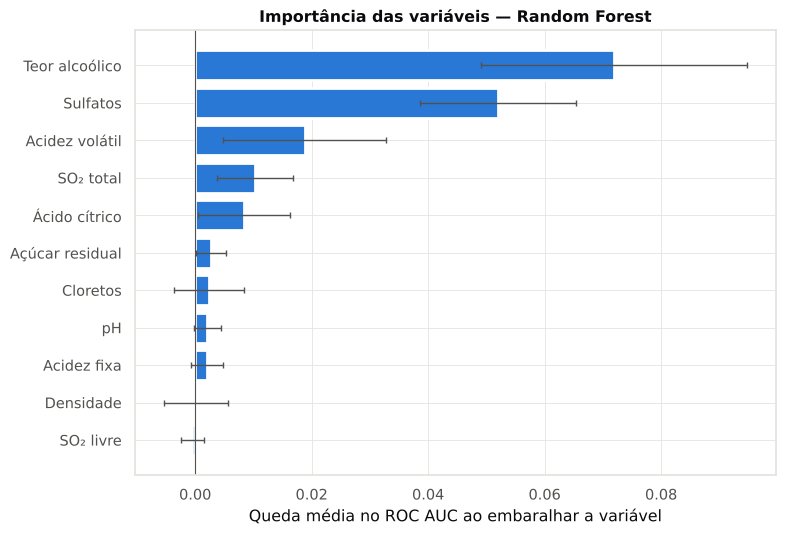

,rotulo,importancia,desvio
0,Teor alcoólico,0.072,0.023
1,Sulfatos,0.052,0.013
2,Acidez volátil,0.019,0.014
3,SO₂ total,0.010,0.007
4,Ácido cítrico,0.008,0.008
5,Açúcar residual,0.003,0.003
6,Cloretos,0.002,0.006
7,pH,0.002,0.002
8,Acidez fixa,0.002,0.003
9,Densidade,0.000,0.006


In [30]:
importancia = evaluation.feature_importance(melhor_modelo, X_test, y_test)
importancia.to_csv(RESULTS_DIR / "importancia_variaveis.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 5.5))
imp_plot = importancia.sort_values("importancia")
ax.barh(imp_plot["rotulo"], imp_plot["importancia"], xerr=imp_plot["desvio"],
        color="#2a78d6", edgecolor="white", linewidth=2,
        error_kw={"ecolor": "#52514e", "elinewidth": 1, "capsize": 2})
ax.axvline(0, color="#52514e", lw=0.8)
ax.set_xlabel("Queda média no ROC AUC ao embaralhar a variável")
ax.set_title(f"Importância das variáveis — {melhor_nome}")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "10_importancia_variaveis.png", dpi=150, bbox_inches="tight")
plt.show()
importancia[["rotulo", "importancia", "desvio"]]

In [31]:
rf = buscas["Random Forest"].best_estimator_.named_steps["model"]
lr = buscas["Regressão Logística"].best_estimator_.named_steps["model"]

comparativo_importancia = pd.DataFrame({
    "RF - importância (impureza)": rf.feature_importances_,
    "Reg. Logística - coeficiente (padronizado)": lr.coef_[0],
}, index=[FEATURE_LABELS[c] for c in FEATURES])
comparativo_importancia = comparativo_importancia.sort_values(
    "RF - importância (impureza)", ascending=False)
comparativo_importancia.to_csv(RESULTS_DIR / "importancia_rf_coef_logistica.csv")
comparativo_importancia

,RF - importância (impureza),Reg. Logística - coeficiente (padronizado)
Teor alcoólico,0.266,0.847
Sulfatos,0.142,0.735
Acidez volátil,0.139,-0.576
Ácido cítrico,0.110,0.116
Densidade,0.072,-0.768
SO₂ total,0.064,-0.585
Cloretos,0.060,-0.441
Acidez fixa,0.052,0.665
pH,0.035,-0.049
Açúcar residual,0.033,0.487


**Leitura das importâncias:**

A importância por permutação, a importância interna do Random Forest e a análise exploratória concordam nos **três fatores principais**:

1. **🥇 Teor alcoólico:** a variável mais importante em todos os métodos. Embaralhá-la derruba o AUC em ~0,07.
2. **🥈 Sulfatos:** o segundo fator no modelo final (queda de ~0,05 no AUC).
3. **🥉 Acidez volátil:** o principal fator **negativo** (queda de ~0,02 no AUC).

Em seguida aparecem **SO₂ total** e **ácido cítrico**, com efeito menor. Açúcar residual, pH, densidade, acidez fixa e SO₂ livre praticamente não alteram o desempenho do modelo, o que é coerente com as correlações fracas ou nulas da seção 2.5.

> **Atenção à Regressão Logística:** ela dá peso alto à **densidade** e à **acidez fixa**, mas isso é efeito da **multicolinearidade** vista na EDA (densidade ligada ao álcool, r = −0,50, e à acidez fixa, r = +0,68). Quando variáveis são correlacionadas, os coeficientes "dividem" o efeito entre si e podem até inverter de sinal. Por isso a importância por permutação, que mede o impacto real no desempenho, é a referência para a interpretação.

Esses resultados **confirmam os insights da EDA**: as mesmas variáveis que se destacaram nos boxplots, no teste de Mann-Whitney e nas correlações são as que o modelo usa para decidir.

### 6.2 Do modelo à previsão: probabilidades calibradas
Com `class_weight='balanced'`, o modelo "puxa" as pontuações para cima, para não ignorar a classe rara. Isso é bom para classificar, mas a pontuação **não pode ser lida como chance real**. Para comunicar previsões a gestores ("este lote tem X% de chance de ser excelente"), **calibramos** as probabilidades com validação cruzada **apenas no treino** (`CalibratedClassifierCV`, método sigmoide).

In [32]:
from sklearn.metrics import brier_score_loss, roc_auc_score

modelo_calibrado = modeling.calibrate_model(melhor_modelo, X_train, y_train, cv=cv)
prob_cal = modelo_calibrado.predict_proba(X_test)[:, 1]

calibracao = pd.DataFrame({
    "Chance média prevista": [prob.mean(), prob_cal.mean()],
    "Taxa real de alta qualidade (teste)": [y_test.mean()] * 2,
    "Brier score (menor = melhor)": [brier_score_loss(y_test, prob),
                                     brier_score_loss(y_test, prob_cal)],
    "ROC AUC": [roc_auc_score(y_test, prob), roc_auc_score(y_test, prob_cal)],
}, index=["Sem calibração", "Calibrado"])
calibracao.to_csv(RESULTS_DIR / "calibracao.csv")
calibracao

,Chance média prevista,Taxa real de alta qualidade (teste),Brier score (menor = melhor),ROC AUC
Sem calibração,0.255,0.132,0.092,0.921
Calibrado,0.130,0.132,0.071,0.918


**Resultado:** sem calibração, a chance média prevista era **25%**, quase o dobro da taxa real de vinhos excelentes no teste (**13%**). Depois da calibração, a média prevista passa a **13,0%**, praticamente igual à realidade, e o erro das probabilidades (Brier score) cai de 0,092 para 0,071. A capacidade de **ordenar** os vinhos é preservada (AUC de 0,92 nos dois casos). Observação técnica: a calibração treina 5 cópias do Random Forest (uma por fold) e combina as probabilidades, então o modelo calibrado é praticamente, mas não exatamente, o mesmo da seção 5 (AUC 0,918 contra 0,921).

A partir daqui, as previsões de negócio (simulador e faixas de ação) usam o **modelo calibrado**, para que "30% de chance" signifique, de fato, cerca de 3 em cada 10 lotes.

<a id="s63"></a>

### 6.3 Previsão de impacto 1: triagem de lotes
**Pergunta de negócio:** se os especialistas avaliarem primeiro os lotes que o modelo considera mais promissores, **quantos vinhos excelentes encontram para cada % de lotes avaliados?**

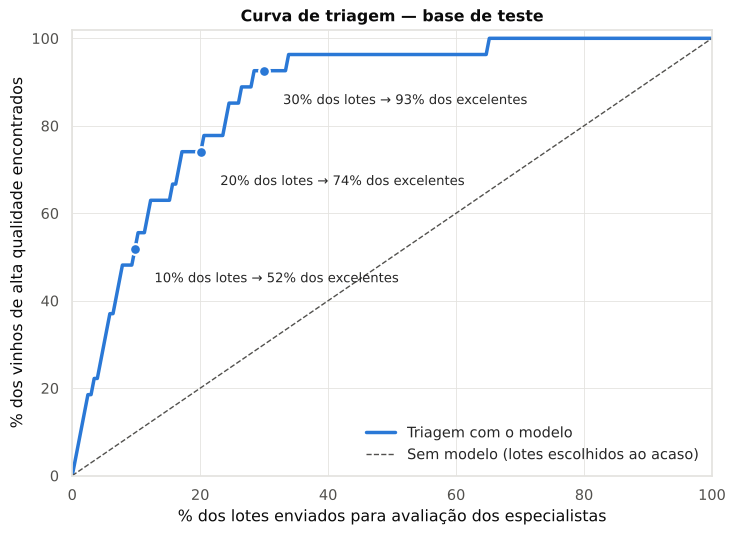

,Lotes avaliados (de 204),% dos vinhos excelentes encontrados
% dos lotes avaliados,,
10%,20,0.519
20%,41,0.741
30%,61,0.926
40%,82,0.963
50%,102,0.963


In [33]:
ganho = evaluation.gains_curve(y_test.values, prob)
ganho.to_csv(RESULTS_DIR / "curva_triagem.csv", index=False)
fig = evaluation.plot_gains_curve(ganho, marks=(0.1, 0.2, 0.3),
                                  path=FIGURES_DIR / "11_curva_triagem.png")
plt.show()

marcos = pd.DataFrame([
    {"% dos lotes avaliados": f"{m:.0%}",
     "Lotes avaliados (de 204)": int(round(m * len(y_test))),
     "% dos vinhos excelentes encontrados": ganho.loc[(ganho['pct_lotes'] - m).abs().idxmin(), "pct_excelentes"]}
    for m in [0.1, 0.2, 0.3, 0.4, 0.5]
]).set_index("% dos lotes avaliados")
marcos

**Resultado:**
- Avaliando apenas os **10% de lotes mais promissores** (20 lotes), os especialistas encontram **52%** dos vinhos excelentes.
- Com **20%** dos lotes, encontram **74%**.
- Com **30%** dos lotes (61 de 204), encontram **93%** (25 dos 27).
- **Sem o modelo**, escolhendo lotes ao acaso, avaliar 30% dos lotes encontraria só ~30% dos excelentes.

### 6.4 Previsão de impacto 2: simulador "e se?"
**Pergunta de negócio:** *se a produção conseguir melhorar as medidas-chave, quanto aumenta a chance prevista de um lote ser excelente?*

Partimos de um **vinho típico**, com todas as medidas na mediana da base, e simulamos, com o modelo calibrado: (1) cada **meta de processo** isolada (álcool e acidez volátil); (2) as **duas metas juntas**; e (3) o **perfil completo** dos vinhos excelentes, que também inclui os sulfatos na faixa de referência. Os sulfatos entram apenas no perfil completo porque são um **marcador** a investigar, e não uma meta de processo (seção 2.5).

> ⚠️ **Leitura correta:** o modelo aprendeu **associações** nos dados. A simulação mostra como a **previsão** muda, não garante que alterar o processo cause esse efeito. Qualquer mudança deve ser validada em **lotes-piloto**.

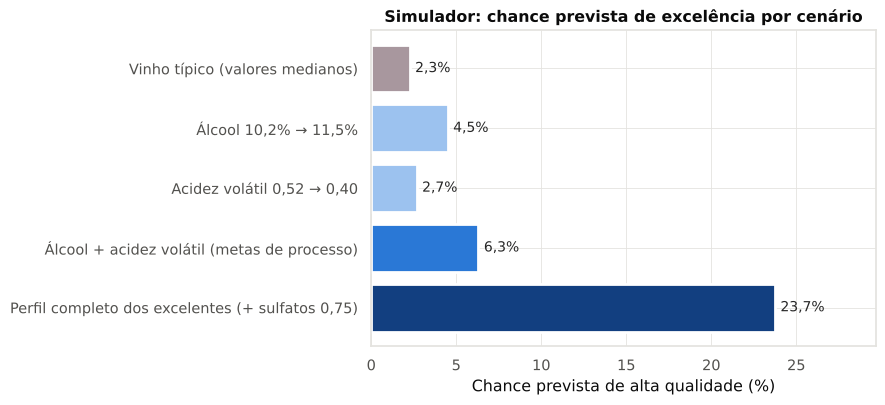

,Teor alcoólico (%),Acidez volátil (g/L),Sulfatos (g/L),Chance de alta qualidade
Cenário,,,,
Vinho típico (valores medianos),"10,2","0,52","0,62","2,3%"
"Álcool 10,2% → 11,5%","11,5","0,52","0,62","4,5%"
"Acidez volátil 0,52 → 0,40","10,2","0,40","0,62","2,7%"
Álcool + acidez volátil (metas de processo),"11,5","0,40","0,62","6,3%"
"Perfil completo dos excelentes (+ sulfatos 0,75)","11,5","0,40","0,75","23,7%"


In [34]:
lote_tipico = df[FEATURES].median()
cenarios = {
    "Vinho típico (valores medianos)": {},
    "Álcool 10,2% → 11,5%": {"alcohol": 11.5},
    "Acidez volátil 0,52 → 0,40": {"volatile acidity": 0.40},
    "Álcool + acidez volátil (metas de processo)": {"alcohol": 11.5, "volatile acidity": 0.40},
    "Perfil completo dos excelentes (+ sulfatos 0,75)": {"alcohol": 11.5, "volatile acidity": 0.40, "sulphates": 0.75},
}
tabela_cenarios = simulation.scenario_table(modelo_calibrado, lote_tipico, cenarios)
tabela_cenarios.to_csv(RESULTS_DIR / "simulador_cenarios.csv")

fig, ax = plt.subplots(figsize=(9, 4.2))
valores = tabela_cenarios["Chance de alta qualidade"] * 100
cores = ["#a8979e", "#9cc2ef", "#9cc2ef", "#2a78d6", "#123f80"]
ax.barh(valores.index[::-1], valores.values[::-1], color=cores[::-1],
        edgecolor="white", linewidth=2)
for i, v in enumerate(valores.values[::-1]):
    ax.annotate(f"{v:.1f}%".replace(".", ","), (v, i), va="center", xytext=(4, 0),
                textcoords="offset points", fontsize=10)
ax.set_xlabel("Chance prevista de alta qualidade (%)")
ax.set_title("Simulador: chance prevista de excelência por cenário")
ax.set_xlim(0, max(valores) * 1.25)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "12_simulador_cenarios.png", dpi=150, bbox_inches="tight")
plt.show()
tabela_cenarios.style.format({"Chance de alta qualidade": "{:.1%}", "Teor alcoólico (%)": "{:.1f}",
                               "Acidez volátil (g/L)": "{:.2f}", "Sulfatos (g/L)": "{:.2f}"}, decimal=",")

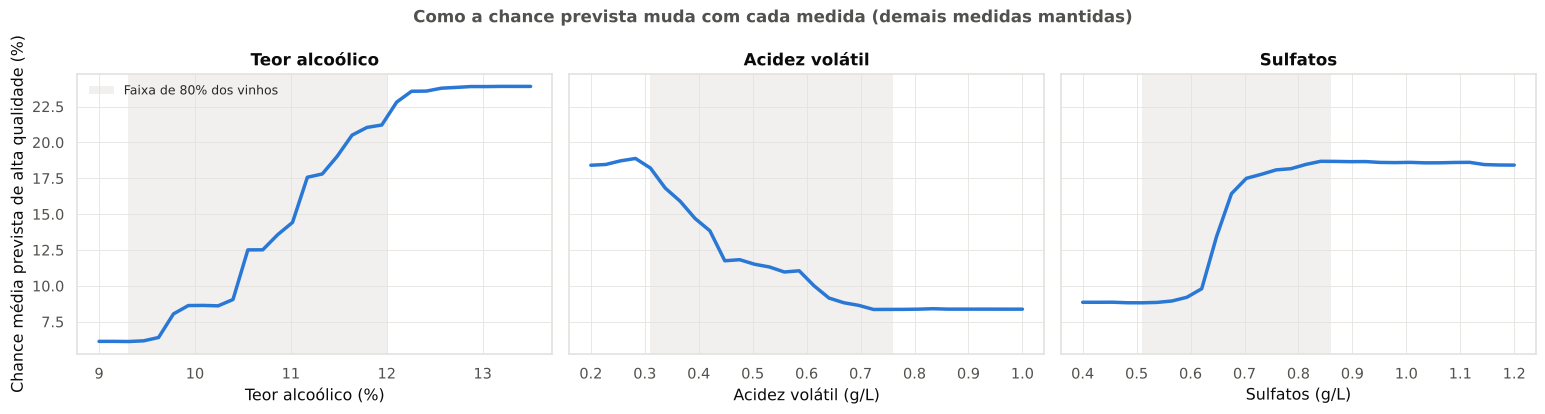

In [35]:
fig = simulation.plot_partial_dependence(
    modelo_calibrado, X_train,
    {"alcohol": np.linspace(9, 13.5, 30),
     "volatile acidity": np.linspace(0.2, 1.0, 30),
     "sulphates": np.linspace(0.4, 1.2, 30)},
    path=FIGURES_DIR / "13_dependencia_parcial.png")
plt.show()

**Leitura do simulador:**
- O **vinho típico** (todas as medidas na mediana: álcool 10,2%, acidez volátil 0,52 g/L, sulfatos 0,62 g/L) tem só **~2%** de chance prevista de ser excelente.
- **Cada meta de processo isolada ajuda pouco:** a chance no máximo dobra (álcool: ~4,5%; acidez volátil: ~2,7%).
- **As duas metas juntas** (álcool 11,5% e acidez volátil 0,40) **triplicam** a chance (~6,3%).
- **O perfil completo dos excelentes**, que também tem sulfatos na faixa de referência (0,75 g/L), chega a **~24%**, cerca de **10 vezes** o vinho típico.

**Implicação:** a excelência depende do **conjunto**, como a análise combinada (seção 2.7) já mostrava. E os sulfatos são justamente a peça que separa "bom processo" (~6%) de "perfil de excelência" (~24%). Por isso a recomendação é **investigar a origem** dessa diferença (nutrição da videira, manejo do SO₂), e não simplesmente adicionar mais.

**Leitura das curvas de dependência parcial** (efeito médio de cada medida, mantendo as demais):
- **Teor alcoólico:** a chance média sobe de ~6% (9% de álcool) para ~24% (acima de 12,3%) e **estabiliza** a partir daí. Não há ganho previsto em ultrapassar ~12,5%.
- **Acidez volátil:** a chance cai de ~19% (até 0,3 g/L) para ~8% (acima de 0,7 g/L). A queda mais forte acontece entre **0,3 e 0,45 g/L**, a faixa onde o controle tem mais efeito.
- **Sulfatos:** há um **salto** entre 0,6 e 0,7 g/L (de ~9% para ~17%), e o efeito **estabiliza acima de ~0,85 g/L**. Adicionar mais sulfatos além dessa faixa não traz benefício previsto, o que é coerente com a "faixa ideal" da seção 2.7.

<a id="s65"></a>

### 6.5 A ferramenta em uso: faixas de ação e lotes de exemplo
Como a previsão seria usada no dia a dia? Propomos classificar cada lote em **três faixas de ação**, de acordo com a chance prevista (modelo calibrado). Em seguida, verificamos na **base de teste** (vinhos que o modelo nunca viu) quantos vinhos de cada faixa eram **realmente** excelentes.

In [36]:
faixas = simulation.band_table(modelo_calibrado, X_test, y_test)
faixas.to_csv(RESULTS_DIR / "faixas_de_acao.csv")
faixas.style.format({"Taxa real de excelência": "{:.0%}", "% dos lotes": "{:.0%}",
                     "% dos excelentes": "{:.0%}"})

,Lotes,Excelentes (real),Taxa real de excelência,% dos lotes,% dos excelentes,Ação recomendada
Faixa de chance prevista,,,,,,
Prioridade (chance ≥ 40%),23,15,65%,11%,56%,Enviar primeiro à avaliação sensorial; candidato à linha premium
Avaliar (chance entre 10% e 40%),38,10,26%,19%,37%,"Avaliar em seguida; revisar álcool, acidez volátil e sulfatos"
Baixo potencial (chance < 10%),143,2,1%,70%,7%,Avaliação simplificada; investigar o processo (ex.: acidez volátil alta)


Para tornar a ferramenta concreta, mostramos **um lote real de cada faixa**, escolhido por critério objetivo (sem seleção manual): o de **maior** chance, o mais próximo de **20%** e o de **menor** chance.

In [37]:
lotes = simulation.example_lots(modelo_calibrado, X_test, y_test,
                                df.loc[X_test.index, "quality"])
lotes.to_csv(RESULTS_DIR / "lotes_exemplo.csv")
lotes.style.format({"Teor alcoólico (%)": "{:.1f}", "Acidez volátil (g/L)": "{:.2f}",
                    "Sulfatos (g/L)": "{:.2f}", "Chance prevista": "{:.0%}"})

,Teor alcoólico (%),Acidez volátil (g/L),Sulfatos (g/L),Chance prevista,Faixa,Ação recomendada,Nota real dos especialistas
Lote,,,,,,,
Lote A,11.7,0.30,0.85,72%,Prioridade (chance ≥ 40%),Enviar primeiro à avaliação sensorial; candidato à linha premium,7
Lote B,11.7,0.53,0.56,20%,Avaliar (chance entre 10% e 40%),"Avaliar em seguida; revisar álcool, acidez volátil e sulfatos",6
Lote C,9.6,0.64,0.54,2%,Baixo potencial (chance < 10%),Avaliação simplificada; investigar o processo (ex.: acidez volátil alta),5


**Leitura das faixas (base de teste, 204 lotes):**

| Faixa | Lotes | Taxa real de excelência | O que significa |
|---|---|---|---|
| **Prioridade** (≥ 40%) | 23 (11%) | **65%** | 2 em cada 3 lotes desta faixa eram excelentes. Concentra **56% de todos os excelentes** em apenas 11% dos lotes |
| **Avaliar** (10% a 40%) | 38 (19%) | **26%** | Faixa intermediária: vale avaliar, e vale revisar as medidas-chave do processo |
| **Baixo potencial** (< 10%) | 143 (70%) | **1,4%** | Só 2 dos 143 lotes eram excelentes. Esses lotes podem ir para avaliação de rotina, sem prioridade |

As faixas são **coerentes com a realidade**: quanto maior a chance prevista, maior a taxa real de excelência. As duas primeiras faixas juntas (30% dos lotes) concentram **93% dos vinhos excelentes**.

**Lotes de exemplo:**
- **Lote A**: álcool 11,7%, acidez volátil 0,30 g/L e sulfatos 0,85 g/L. É o "perfil ideal" completo, com **72% de chance**, e de fato recebeu **nota 7**.
- **Lote B**: álcool alto (11,7%), mas **acidez volátil (0,53) e sulfatos (0,56) fora da faixa ideal**. Chance de **20%**, e recebeu **nota 6**. É o caso em que o simulador indica onde agir: com acidez volátil e sulfatos corrigidos, esse lote estaria no perfil do lote A.
- **Lote C**: álcool baixo (9,6%) e acidez volátil alta (0,64 g/L). Chance de **2%**, e recebeu **nota 5**.

### 6.6 Quão certos são esses números? (intervalos de confiança)
A base de teste tem 204 lotes e só 27 excelentes. Para não vender uma precisão que não existe, calculamos o **intervalo de confiança de 95% (método de Wilson)** dos principais resultados.

In [38]:
casos = {
    "Excelentes encontrados pelo modelo (recall)": (21, 27),
    "Excelentes encontrados avaliando 30% dos lotes": (25, 27),
    "Taxa de excelência na faixa Prioridade": (int(faixas.iloc[0]["Excelentes (real)"]), int(faixas.iloc[0]["Lotes"])),
    "Taxa de excelência na faixa Avaliar": (int(faixas.iloc[1]["Excelentes (real)"]), int(faixas.iloc[1]["Lotes"])),
    "Taxa de excelência na faixa Baixo potencial": (int(faixas.iloc[2]["Excelentes (real)"]), int(faixas.iloc[2]["Lotes"])),
}
incerteza = pd.DataFrame([
    {"Resultado": nome, "Observado": f"{k} de {n}", "Taxa": k / n,
     "IC 95% - mínimo": evaluation.wilson_interval(k, n)[0],
     "IC 95% - máximo": evaluation.wilson_interval(k, n)[1]}
    for nome, (k, n) in casos.items()
]).set_index("Resultado")
incerteza.to_csv(RESULTS_DIR / "intervalos_confianca.csv")
incerteza.style.format({"Taxa": "{:.0%}", "IC 95% - mínimo": "{:.0%}", "IC 95% - máximo": "{:.0%}"})

,Observado,Taxa,IC 95% - mínimo,IC 95% - máximo
Resultado,,,,
Excelentes encontrados pelo modelo (recall),21 de 27,78%,59%,89%
Excelentes encontrados avaliando 30% dos lotes,25 de 27,93%,77%,98%
Taxa de excelência na faixa Prioridade,15 de 23,65%,45%,81%
Taxa de excelência na faixa Avaliar,10 de 38,26%,15%,42%
Taxa de excelência na faixa Baixo potencial,2 de 143,1%,0%,5%


**Leitura:** mesmo no cenário mais conservador (limite inferior do intervalo), o modelo encontra **mais da metade** dos excelentes (≥ 59%). A triagem de 30% dos lotes encontra **pelo menos ~77%** deles, contra ~30% ao acaso. As faixas **não se sobrepõem** entre "Prioridade" (45% a 81%) e "Baixo potencial" (0% a 5%). Os números exatos devem ser lidos como **ordem de grandeza**, e o piloto recomendado serve justamente para medi-los com mais precisão.

<a id="s67"></a>

### 6.7 Previsão de impacto 3: o que muda na operação
Há duas formas de usar as faixas no dia a dia:

- **Modo A, priorização:** **todos** os lotes continuam passando pela avaliação completa, mas na ordem sugerida pelo modelo. O ganho é **tempo**: os vinhos premium são identificados primeiro, o que adianta decisões comerciais.
- **Modo B, triagem:** os lotes de **baixo potencial** passam por uma avaliação **simplificada** (por exemplo, um avaliador em vez do painel completo). O ganho é **custo**: menos avaliações completas.

Abaixo, projetamos o Modo B para **1.000 lotes**, usando as proporções observadas na base de teste.

In [39]:
lotes_safra = 1_000
prop_baixo = faixas.iloc[2]["% dos lotes"]
excelentes_fora = faixas.iloc[2]["% dos excelentes"]
impacto = pd.DataFrame({
    "Sem o modelo": [lotes_safra, 0, "100%"],
    "Com triagem (Modo B)": [round(lotes_safra * (1 - prop_baixo)),
                             round(lotes_safra * prop_baixo),
                             f"{1 - excelentes_fora:.0%}"],
}, index=["Lotes com avaliação completa", "Lotes com avaliação simplificada",
          "Excelentes que passam pela avaliação completa"])
impacto.to_csv(RESULTS_DIR / "impacto_operacional.csv")
print(f"Redução de avaliações completas: {prop_baixo:.0%}")
impacto

Redução de avaliações completas: 70%


,Sem o modelo,Com triagem (Modo B)
Lotes com avaliação completa,1000,299
Lotes com avaliação simplificada,0,701
Excelentes que passam pela avaliação completa,100%,93%


**Leitura:** com a triagem, cerca de **700 de cada 1.000 lotes** deixariam de precisar do painel completo, ou seja, **~70% menos avaliações completas**, e ainda assim **~93% dos vinhos excelentes** continuariam no fluxo prioritário. O risco é perder ~7% dos excelentes na avaliação simplificada: em 1.000 lotes com ~135 excelentes, seriam ~10. Por isso a avaliação simplificada deve continuar existindo, e o piloto deve medir esse risco.

**Quanto isso vale em R$?** A base não traz custos nem preços. Por isso, em vez de "inventar" um valor, calculamos uma **regra de decisão** que vale para qualquer vinícola, e depois um **exemplo ilustrativo** com premissas explícitas, que devem ser trocadas pelos valores reais.

**Regra de equilíbrio:** a triagem compensa enquanto o prejuízo de deixar de identificar um vinho premium for **menor que ~72 vezes** a economia de uma avaliação (custo da avaliação completa menos o da simplificada). Isso porque, a cada lote, a triagem poupa ~0,70 avaliação completa e arrisca ~0,0098 vinho premium (0,70 ÷ 0,0098 ≈ 72). Na prática, o multiplicador é o inverso da taxa de excelentes na faixa de baixo potencial (143 ÷ 2 ≈ 72).

⚠️ **Incerteza:** esse multiplicador se apoia em apenas **2 vinhos excelentes** na faixa de baixo potencial. Pelo intervalo de confiança da seção 6.6 (0,4% a 5%), ele pode variar de **~20 a ~260 vezes**. No cenário conservador (~20 vezes), a triagem só compensa se um premium perdido valer menos que ~20 avaliações economizadas. Medir esse número com precisão é um dos objetivos do piloto.

In [40]:
# PREMISSAS ILUSTRATIVAS: substitua pelos valores reais da vinícola
custo_avaliacao_completa = 600      # R$ por lote (painel de especialistas)
custo_avaliacao_simplificada = 100  # R$ por lote (um avaliador)
valor_premium_perdido = 15_000      # R$ perdidos se um lote premium não for identificado

premium_fora_por_lote = faixas.iloc[2]["Excelentes (real)"] / faixas["Lotes"].sum()
equilibrio = simulation.breakeven_premium_value(
    prop_baixo, premium_fora_por_lote, custo_avaliacao_completa, custo_avaliacao_simplificada)
print(f"Excelentes na faixa de baixo potencial, por lote avaliado: {premium_fora_por_lote:.4f}")
print(f"Multiplicador de equilíbrio: {prop_baixo / premium_fora_por_lote:.1f} x a economia por avaliação")
valor_fmt = f"{equilibrio:,.0f}".replace(",", ".")
print(f"Com as premissas acima, a triagem compensa se um premium perdido valer menos que R$ {valor_fmt}")

cenario = simulation.financial_scenario(
    lotes_safra, prop_baixo, premium_fora_por_lote,
    custo_avaliacao_completa, custo_avaliacao_simplificada, valor_premium_perdido)
pd.Series(cenario, name="Exemplo ilustrativo (1.000 lotes)").to_frame().style.format("{:,.0f}", thousands=".")

Excelentes na faixa de baixo potencial, por lote avaliado: 0.0098
Multiplicador de equilíbrio: 71.5 x a economia por avaliação
Com as premissas acima, a triagem compensa se um premium perdido valer menos que R$ 35.750


,Exemplo ilustrativo (1.000 lotes)
Lotes com avaliação simplificada,701
Economia em avaliações (R$),350.490
Premium possivelmente não identificados,10
Perda potencial (R$),147.059
Resultado líquido (R$),203.431


In [41]:
# Sensibilidade: resultado líquido (R$ mil por 1.000 lotes) para diferentes premissas
economias = [200, 500, 1_000]          # custo completa - simplificada (R$ por lote)
valores_premium = [5_000, 15_000, 30_000, 60_000]
sens = pd.DataFrame(
    [[simulation.financial_scenario(lotes_safra, prop_baixo, premium_fora_por_lote,
                                    e, 0, v)["Resultado líquido (R$)"] / 1_000
      for v in valores_premium] for e in economias],
    index=[f"Economia de R$ {e} por avaliação" for e in economias],
    columns=[f"Premium perdido vale R$ {v:,}".replace(",", ".") for v in valores_premium])
sens.to_csv(RESULTS_DIR / "sensibilidade_financeira.csv")
sens.style.format("{:,.0f}", thousands=".").background_gradient(cmap="RdBu", vmin=-400, vmax=400)

,Premium perdido vale R$ 5.000,Premium perdido vale R$ 15.000,Premium perdido vale R$ 30.000,Premium perdido vale R$ 60.000
Economia de R$ 200 por avaliação,91,-7,-154,-448
Economia de R$ 500 por avaliação,301,203,56,-238
Economia de R$ 1000 por avaliação,652,554,407,113


**Leitura:** no exemplo ilustrativo (avaliação completa a R$ 600, simplificada a R$ 100 e R$ 15 mil de perda por premium não identificado), a triagem **economiza ~R$ 350 mil a cada 1.000 lotes** e arrisca ~R$ 147 mil em premium não identificados (pior caso), um **saldo positivo de ~R$ 200 mil**. A tabela de sensibilidade mostra **quando a triagem deixa de compensar**: se o premium perdido valer muito e a economia por avaliação for pequena (células negativas). Nesse caso, a empresa deve usar o **Modo A** (só priorização), que não tem risco de perda.

> Os valores em R$ são **premissas ilustrativas**, não dados da base. A regra de equilíbrio (~72 vezes a economia por avaliação, com faixa provável de ~20 a ~260 vezes) vem dos dados e vale para qualquer custo, mas deve ser confirmada no piloto.

### 6.8 Implicações para o processo de produção
Os resultados apontam **alavancas concretas** para enólogos e produtores:

| Fator | O que os dados mostram | Meta de referência (dos dados) | Possível ação no processo |
|---|---|---|---|
| **Teor alcoólico** | Fator nº 1. A chance prevista sobe até ~12,3% e depois estabiliza | ≥ 11,5% | Controlar a **maturação da uva e o ponto de colheita** (°Brix) e garantir uma **fermentação completa** |
| **Acidez volátil** | Principal fator negativo. Maior queda entre 0,3 e 0,45 g/L | < 0,4 g/L | Reforçar **higiene**, **controle de temperatura** e **proteção contra oxigênio** (que favorece bactérias acéticas). Medir ao longo da produção como **alerta precoce** |
| **Sulfatos** | Marcador associado à qualidade, com faixa ideal entre 0,65 e ~0,85 g/L | 0,65 a 0,85 g/L (referência, não meta) | **Investigar a origem** da diferença (nutrição da videira, manejo do SO₂) e testar em piloto, **sem elevar o SO₂ total**, que tem relação negativa com a nota |
| **Ácido cítrico** | Ligeiramente maior nos vinhos bons; associado a menos acidez volátil | — | Avaliar o **equilíbrio de acidez** e o frescor |

**Uso operacional do modelo:**
1. **Triagem da avaliação sensorial:** as faixas "Prioridade" e "Avaliar" (30% dos lotes) concentram **93% dos vinhos excelentes**. No Modo A (priorização), os premium são identificados primeiro. No Modo B (triagem), há **~70% menos avaliações completas** (seção 6.7).
2. **Posicionamento comercial:** os lotes da faixa "Prioridade" (65% de taxa real de excelência) são candidatos naturais a uma **linha premium**, após a confirmação sensorial.
3. **Alerta de processo:** lotes na faixa "Baixo potencial" com acidez volátil alta indicam **onde investigar** a fermentação e a higiene, ainda durante a produção.

O modelo **não substitui o especialista**: ele direciona o tempo dele para onde há mais potencial e transforma a avaliação final em uma **informação antecipada** para a produção.

### 6.9 Limitações e próximos passos
- **Base pequena e desbalanceada:** com 27 vinhos bons no teste, cada acerto ou erro muda bastante as métricas. Mais dados, sobretudo de vinhos excelentes, tornariam o modelo mais confiável.
- **Somente Vinho Verde tinto e sem variáveis de contexto:** a base não traz uva, safra, região, preço ou processo de envelhecimento, fatores que também influenciam a qualidade. As medidas são do vinho pronto: em produção, seria preciso validar o modelo com medidas de etapas intermediárias.
- **Incerteza:** os resultados do teste vêm de 27 vinhos excelentes, por isso têm intervalos de confiança largos (seção 6.6).
- **Correlação não é causalidade:** o modelo e o simulador mostram associações. Mudanças no processo devem ser testadas em pequenos lotes antes de aplicadas em escala.
- **Próximos passos técnicos:** escolher o limiar de decisão em uma base de validação dedicada, retreinar o modelo com os dados do piloto e monitorar o desempenho a cada safra. (O *oversampling* com SMOTE já foi testado na seção 4.1 e não trouxe ganho.)

---
<a id="s7"></a>

## 7. Conclusão
**Respondendo à pergunta de negócio:** sim, as medidas físico-químicas permitem **antecipar com boa confiabilidade** quais vinhos serão avaliados como de alta qualidade.

1. **O que define um vinho excelente nesta base:** teor alcoólico alto, acidez volátil baixa e sulfatos em uma faixa ideal, **atuando em conjunto**. São as três medidas com os maiores efeitos estatísticos, e nenhuma delas isolada é suficiente.
2. **O modelo escolhido (Random Forest)**, selecionado pela validação cruzada entre 5 algoritmos, encontra **quase 4 em cada 5 vinhos excelentes** em vinhos nunca vistos (78%; ROC AUC de 0,92), com o melhor equilíbrio entre acertos e alarmes falsos e sem sobreajuste que comprometa o uso.
3. **O impacto prático é mensurável:** avaliar 30% dos lotes encontra 93% dos excelentes; as faixas de chance acompanham a realidade (65% de excelentes na faixa de prioridade contra 1,4% na de baixo potencial); e a triagem permitiria **~70% menos avaliações completas**.
4. **Próximo passo recomendado:** um **piloto na próxima safra**, usando a triagem e as metas de processo em um grupo de lotes e comparando os resultados com os lotes conduzidos da forma atual.

---
<a id="s8"></a>

## 8. Verificação de reprodutibilidade
Os textos deste notebook citam números obtidos na execução de referência (versões em `requirements.txt`, `RANDOM_STATE = 42`). A célula abaixo **recalcula** esses números e confere se batem com o texto. Se alguma linha mostrar ⚠️, a execução atual gerou um valor diferente (por exemplo, por causa de outra versão de biblioteca) e o texto correspondente deve ser revisto.

In [42]:
from sklearn.metrics import f1_score, roc_auc_score, recall_score

citados = {
    "Duplicados removidos": (125, n_dup, 0),
    "Vinhos após a limpeza": (1018, len(df), 0),
    "% de alta qualidade": (0.135, df[TARGET].mean(), 0.001),
    "Modelo escolhido": ("Random Forest", melhor_nome, None),
    "F1 do modelo no teste": (0.592, f1_score(y_test, melhor_modelo.predict(X_test)), 0.001),
    "ROC AUC do modelo no teste": (0.921, roc_auc_score(y_test, prob), 0.001),
    "Recall do modelo no teste": (21 / 27, recall_score(y_test, melhor_modelo.predict(X_test)), 0.001),
    "Excelentes encontrados com 30% dos lotes": (0.926, ganho.loc[(ganho['pct_lotes'] - 0.3).abs().idxmin(), 'pct_excelentes'], 0.001),
    "Taxa real na faixa Prioridade": (15 / 23, faixas.iloc[0]["Taxa real de excelência"], 0.001),
    "Taxa real na faixa Baixo potencial": (2 / 143, faixas.iloc[2]["Taxa real de excelência"], 0.001),
    "Simulador: perfil completo": (0.237, tabela_cenarios["Chance de alta qualidade"].iloc[-1], 0.002),
    "Excelentes com álcool ≥ 12,5% (slide 5)": (0.431, taxa_alcool["% alta qualidade"].iloc[-1], 0.001),
    "Excelentes com acidez volátil < 0,3 (slide 6)": (0.378, taxa_acidez["% alta qualidade"].iloc[0], 0.001),
}
verif = []
for item, (esperado, obtido, tol) in citados.items():
    ok = (esperado == obtido) if tol is None else abs(float(esperado) - float(obtido)) <= tol
    verif.append({"Número citado no texto": item, "Esperado": esperado,
                  "Obtido nesta execução": obtido, "Confere?": "✅" if ok else "⚠️ revisar"})
verificacao = pd.DataFrame(verif).set_index("Número citado no texto")
print("Todos os números conferem!" if (verificacao["Confere?"] == "✅").all()
      else "Atenção: há números diferentes do texto.")
verificacao

Todos os números conferem!


,Esperado,Obtido nesta execução,Confere?
Número citado no texto,,,
Duplicados removidos,125,125,✅
Vinhos após a limpeza,1018,1018,✅
% de alta qualidade,0.135,0.135,✅
Modelo escolhido,Random Forest,Random Forest,✅
F1 do modelo no teste,0.592,0.592,✅
ROC AUC do modelo no teste,0.921,0.921,✅
Recall do modelo no teste,0.778,0.778,✅
Excelentes encontrados com 30% dos lotes,0.926,0.926,✅
Taxa real na faixa Prioridade,0.652,0.652,✅
